# Random Forest MultiClassifier Explainable A.I. Manuscript

Andrew E. Davidson   
aedavids@ucsc.edu  
Date: 2025-07-21.  
Copyright (c) 2025-2026, Regents of the University of California All rights reserved.  
https://polyformproject.org/licenses/noncommercial/1.0.0  

## <span style="color:red;background-color:yellow;">create waterfall and beeswarm plots for manscripts</span>

Elife multiclassification with all 6 class has a lot of mis-classification errors. almost all samples are classified as "Lung_Cancer". Use SHAP to try and identify what causes the mis classification errors

Copy of multiClassifierXAI_summary.ipynb. 

do not use 5 class elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy data set. this is mulitclassifier we used in the simulation manuscript. This data set is comparable to Chen's how ever it does not tell the G.I. tract story well. ie stomach misclassified as colorectal. colorectal is often mis-classified but almost no other samples are mis classified as colorectal

use the 4 class elifeMultiClassifierFrom400BinaryDropHealthyLung data set

**reference**. 
* multiClassifiler.ipynb
* MultiClassifilerResults.ipynb
* binaryClassifierXAI/binaryClassifierXAI_summary.ipynb

In [1]:
defaultNotebookName="multiClassifierXAI_manuscript"

from cliUtilities import configLogging
import logging

# rootLogger = configLogging(logLevel="INFO")
rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-10-21 12:57:28,168 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-10-21 12:57:28,169 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/fagazi/src/python:/private/home/aedavids/fagazi/src/jupyterNotebooks]
2026-10-21 12:57:28,169 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/fagazi/src/python/cliUtilities.py]
2026-10-21 12:57:28,170 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers]


In [2]:
from __future__ import annotations 
import copy

from IPython.display import display, Image
# from IPython.display import HTML
# import json

from matplotlib.figure import Figure
from matplotlib.axes import Axes
from matplotlib.collections import LineCollection, PathCollection
import matplotlib.pyplot as plt
from matplotlib.text import Text
from matplotlib.transforms import ScaledTranslation
# set up matplotlib default final artwork complient styles
from plots.plotPanel import natureManuscriptStyle
plt.rcParams.update(natureManuscriptStyle)


import numpy.typing as npt
import numpy as np
import os
from typing import Any
import pandas as pd
from pathlib import Path
import shap
from shap import Explanation
from sklearn.base import BaseEstimator
from sklearn.ensemble import RandomForestClassifier
# from textwrap import fill
import time

# local imports
from notebookUtils import appendToPYTHONPATH, getNotebookName

ORIG_PYTHONPATH = os.environ['PYTHONPATH']

extraRNA_PythonPath1 = '/private/home/aedavids/extraCellularRNA' 
extraRNA_PythonPath2 = '/private/home/aedavids/extraCellularRNA/src'
appendToPYTHONPATH([extraRNA_PythonPath1, extraRNA_PythonPath2])

from archive.dataTypes import  ModelConfig
from archive.archiveUtilities import getModel, getRealData, loadArchive, printDictTree 
from archive.archiveUtilities import getTrainingData
from archive.archiveUtilities import saveFigure
import data.geneAnnotator

from models.configMLWorkflow import configMultiLoad, configTrain # configEvaluate 

from explainability.gseaUtilities import createEnsembleToHUGOMap
from explainability.plotSHAP import plotWaterfall
from explainability.shapUtilities import describeExplainerStr, getSHAPValues, validateData

from plots.plotPanel import checkForFonts, combineFiguresLayout, getSubplotWidthAndHeight 
from plots.plotPanel import displayPDFInNotebook, natureManuscriptStyle, Panel
from plots.plotPanel import setFigureFont
from plots.plotUtilities import changeYlabels, saveDataFrameImage, saveWrappedDataFrameImage
from plots.plotUtilities import urlify

from utilities import isOrderedCategoricalSeries
from utilities import smartDisplay

notebook_start_time = time.time()
print("⏱️ Notebook started.")

/private/home/aedavids/miniconda3/envs/fagazi/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-21 12:57:31,169 WARNING notebookUtils.py appendToPYTHONPATH() line:40] [Updated PYTHONPATH: /private/home/aedavids/fagazi/src/python:/private/home/aedavids/fagazi/src/jupyterNotebooks:/private/home/aedavids/extraCellularRNA:/private/home/aedavids/extraCellularRNA/src]


⏱️ Notebook started.


In [3]:
# font check 
# make sure final artwork complient fonts are avalible on local machine
checkForFonts()

Arial: not available
Helvetica: not available
DejaVu Sans: /private/home/aedavids/miniconda3/envs/fagazi/lib/python3.13/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Aptos: not available


In [4]:
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')
notebookOutDir = f'{notebookDir}/{notebookName}.out'

# 8/27/26 add data set name to img out dir
# imgOutDir = f'{notebookOutDir}/img'
# os.makedirs(imgOutDir, exist_ok=True)



notebookName: multiClassifierXAI_manuscript
notebookDir: /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers


In [5]:
# _G : global use to insure we do not pick up globals in function by accident 
# durring refactoring

simulatedDataRootDir_G = "/private/groups/kimlab/aedavids/fagazi/simulatedData"
scratchDataRootDir_G = "/scratch/aedavids/fagazi/simulatedData"

realDataRoot_G = "/private/groups/kimlab/data/elife"
realDataPath_G = f'{realDataRoot_G}/elife_all_norm_counts_2023-05-18.csv'
realMetaDataPath_G = f'{realDataRoot_G}/elife_scaled_metaData_2023-05-18.csv'

In [6]:
# load mapping from ensemble to HUGO
# ref : src/jupyterNotebooks/elifeVsTCGA/gsea.ipynb
v39GeneMapPath= f'/scratch/aedavids/fagazi/gsea.out/v39GeneMap.csv'
v39GeneMapDF = createEnsembleToHUGOMap(mapFilePath=v39GeneMapPath)

print(f'v39GeneMapDF.shape : {v39GeneMapDF.shape}')
smartDisplay(v39GeneMapDF.head(n=2))
print()
smartDisplay(v39GeneMapDF.tail(n=2))

2026-10-21 12:57:31,402 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/gsea.out/v39GeneMap.pandas.h5]


v39GeneMapDF.shape : (77116, 7)


,HUGO,ENSG,base,version,originalENSG,bioType,isENSG
39389,DDX11L1,ENSG00000223972.5,ENSG00000223972,5,ENSG00000223972.5,"[processed_transcript, transcribed_unprocessed_pseudogene]",True
41633,WASH7P,ENSG00000227232.5,ENSG00000227232,5,ENSG00000227232.5,[unprocessed_pseudogene],True


,HUGO,ENSG,base,version,originalENSG,bioType,isENSG
13383,(TTCGAGTCCA)n,(TTCGAGTCCA)n,(TTCGAGTCCA)n,NaN,(TTCGAGTCCA)n,[repeatMask],False
12794,(TGTGTGGTG)n,(TGTGTGGTG)n,(TGTGTGGTG)n,NaN,(TGTGTGGTG)n,[repeatMask],False


In [7]:
# path to pretrained models
multiClassifiersRootOutDir_G = f'{notebookDir}/multiClassifiers.out'

In [8]:
elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # "Healthy_donor",
                        # make sure categories[0] is the negative diagnostic test class
                        categories = [  "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer", "Lung_Cancer", "Stomach_Cancer" ],
                    )

elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G.abstract = "5 class multi-classfiler data set set used in simulation manscript"


In [9]:
elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom400BinaryDropHealthy+Lung",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom400Binary.sh.out_best400_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        # "Healthy_donor", "Lung_Cancer",
                        categories = [ "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer",  "Stomach_Cancer" ],
                    )

elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G.abstract = "4 class multi-classfiler data set set used in simulation manscript"

# debug <span style="color:red;background-color:yellow;">9/24 debug select data set</span>

In [10]:
# dataSrcRunConfig_G = elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G # manuscript feature importance and upset plot
dataSrcRunConfig_G = elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G # manuscript waterfall plots

imgOutDir = f'{notebookOutDir}/{dataSrcRunConfig_G.dataSetName}/img'
os.makedirs(imgOutDir, exist_ok=True)
print(f'imgOutDir : {imgOutDir}')

imgOutDir : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img


In [11]:
def formatUpsetPlotFinalArtwork(
    fig: Figure,
    axDict: dict[str, Axes],
    widthMm: float = 180,
    heightMm: float = 110,
    fontFamily: str = "DejaVu Sans",
    fontSize: float = 7,
    countFontSize: float = 6,
    markerSize: float = 9,
    lineWidth: float = 0.6,
) -> Figure:
    """Format an existing horizontal UpSet plot for final artwork.

    Modifies and returns the supplied figure.
    markerSize is in points squared; lineWidth is in points.
    """

    fig.set_size_inches(widthMm / 25.4, heightMm / 25.4)
    fig.suptitle("")

    # Repair single-element array coordinates generated by UpSet.
    # This must happen before drawing the figure.
    for text in fig.findobj(match=Text):
        x, y = text.get_position()

        if isinstance(x, np.ndarray) and x.size == 1:
            x = x.item()

        if isinstance(y, np.ndarray) and y.size == 1:
            y = y.item()

        text.set_position((x, y))

    matrixAx = axDict["matrix"]
    totalsAx = axDict["totals"]
    intersectionAx = axDict["intersections"]

    # Format intersection dots and their connecting lines.
    for collection in matrixAx.collections:
        if isinstance(collection, PathCollection):
            collection.set_sizes([markerSize])
        elif isinstance(collection, LineCollection):
            collection.set_linewidth(lineWidth)

    # Replace underscores in set names.
    ticks = matrixAx.get_yticks()
    labels = [
        label.get_text().replace("_", " ")
        for label in matrixAx.get_yticklabels()
    ]
    matrixAx.set_yticks(ticks, labels=labels)

    # Move the total-size bars left, leaving room for set names.
    pos = totalsAx.get_position()
    totalsAx.set_position([
        0.04,
        pos.y0,
        0.055,
        pos.height,
    ])
    totalsAx.set_xlabel("Set size")

    # Leave headroom for vertical count labels.
    bottom, top = intersectionAx.get_ylim()
    intersectionAx.set_ylim(bottom, max(top, 350))

    for ax in fig.axes:
        ax.tick_params(
            axis="both",
            which="both",
            labelsize=fontSize,
        )

    # Materialize tick labels, then apply consistent fonts everywhere.
    fig.canvas.draw()

    for text in fig.findobj(match=Text):
        text.set_fontfamily(fontFamily)
        text.set_fontsize(fontSize)
        text.set_fontweight("normal")

    # Rotate intersection counts to prevent adjacent values overlapping.
    for text in intersectionAx.texts:
        text.set_fontsize(countFontSize)
        text.set_rotation(90)
        text.set_ha("center")
        text.set_va("bottom")

    # Give total-count labels a small, fixed separation from the bars.
    # Resetting this transform avoids accumulating shifts on repeat calls.
    countTransform = (
        totalsAx.transData
        + ScaledTranslation(-2 / 72, 0, fig.dpi_scale_trans)
    )

    for text in totalsAx.texts:
        text.set_fontsize(countFontSize)
        text.set_ha("right")
        text.set_transform(countTransform)

    return fig

In [12]:
def generateUpsetPlot() ->  dict[str, tuple[Figure, dict[str, Axes]]] :
    ''' 
    TODO
    '''
    deseqResultsDir = '/private/groups/kimlab/data/elife/1vsAll/cromwell.output'
    findModule = 'selectFeatures.createBestCreateSignatureGeneConfig'
    #  outDir = aedwip '/scratch/aedavids/fagazi/simulatedData/./elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results'
    resultsSuffix = 'results'
    topN = 300
    # local_title=`printf "best%s_%s" $topN $resultsSuffix` # do not uses spaces, title will be part of file paths


    vargs = [
            '--design', 'tilda_gender_category',
            '--padjThreshold', '0.1',
            '--lfcThreshold', '1.0',
            '--dataSetName', 'elife',
            '--number',  str(topN), 
            '--title', "Random Forest Cancer Multi-classifier ",
            '--localCacheRoot', upsetOutDir
        ] 
        
    inCommandLineArgsList = [
        '--deseqResultsDir', deseqResultsDir,
        # '--findModule', findModule,
        '--findModule', 'selectFeatures.createBestCreateSignatureGeneConfig',
        '--out', upsetOutDir,  
        '--resultsSuffix', resultsSuffix,
        '--vargs', *vargs # <-- splat the list so they become multiple args
    ]
    
    # selectFeatures.selectFeaturesDriver.main(inCommandLineArgsList)
    # try : 
    #     sfd.main( inCommandLineArgsList )
    # except SystemExit:
    #     print(f"main() exited ")  
    #     # pass 
    # finally:
    #     plt.close("all")     
    upsetPlotDict = sfd.main(
        inCommandLineArgsList,
        returnPlots=True,
    )

    # Suppress automatic display of all the intermediate plots.
    # The dictionary still retains the figure objects.
    plt.close("all")
    
    return upsetPlotDict

# <span style="color:red;background-color:yellow;">9/23 re-run selectFeatures.selectFeaturesDriver stage of generateSamplesPipeline.sh to create a pdf version of upset plots. </span>

ref: 
- src/bin/elifeMultiClassifierFrom300_1vsAllRelaxed.sh
- src/bin/generateSamplesPipeline.sh
- 

In [13]:
from selectFeatures import selectFeaturesDriver as sfd

if dataSrcRunConfig_G.dataSetName == "elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy" :

    upsetOutDir = f'{notebookOutDir}/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/img/createBestCreateSignatureGeneConfig.out'
    os.makedirs(upsetOutDir, exist_ok=True)
    
    def createPDFUpsetPlots():
        ''' 
        dataSetName = "elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy",

        we changed saveImage, it will now save png and pdf versions
        '''
        upsetPlotDict = generateUpsetPlot()
        print(f' AEDWIP DEBUG {upsetPlotDict.keys()}')

        allDegreesFig, axDict = upsetPlotDict["allDegrees"]

        finalArtworkFig = formatUpsetPlotFinalArtwork(
            fig=allDegreesFig,
            axDict=axDict,
            widthMm=180,
            heightMm=110,
            fontFamily=natureManuscriptStyle["font.family"],
            fontSize=7,
            countFontSize=6,
            markerSize=9,
        )

        display(finalArtworkFig)
        return finalArtworkFig    
        
    finalArtworkFig = createPDFUpsetPlots()
    
    outputStem = Path(upsetOutDir) / "upsetPlot.out" / (
        "ExtDataFigure_M1_Random-Forest-Cancer-Multi-classifier--allDegrees"
    )
    outputStem.parent.mkdir(parents=True, exist_ok=True)
    logger.warning(f'saving upset plots to {outputStem}')


    # Preserve the exact canvas dimensions and embed TrueType fonts in PDF.
    with plt.rc_context({
        "pdf.fonttype": 42,
        "savefig.bbox": None,
        }):
        finalArtworkFig.savefig(
            outputStem.with_suffix(".pdf"),
            bbox_inches=None,
            facecolor="white",
        )

        finalArtworkFig.savefig(
            outputStem.with_suffix(".png"),
            dpi=600,
            bbox_inches=None,
            facecolor="white",
        )
    
    # # display(Image('/private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/img/createBestCreateSignatureGeneConfig.out/upsetPlot.out/Random-Forest-Cancer-Multi-classifier--min_degree=1,_max_degree=1.png'))
    # upsetPath = f'{upsetOutDir}/upsetPlot.out/Random-Forest-Cancer-Multi-classifier--allDegrees.png'
    # display(Image(upsetPath))
else :
    logger.warning(f'skipping createPDFUpsetPlots() only works for elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy')

2026-10-21 12:57:32,034 WARNING 782472562.py <module>() line:64] [skipping createPDFUpsetPlots() only works for elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy]


# load and train

In [14]:
print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
configMultiLoad(dataSrcRunConfig_G)

2026-10-21 12:57:32,042 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom400Binary.sh.out_best400_results/formatSynthetics.py.out/X.pandas.h5]


data set : elifeMultiClassifierFrom400BinaryDropHealthyLung



2026-10-21 12:57:46,745 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom400Binary.sh.out_best400_results/formatSynthetics.py.out/y.pandas.h5]
2026-10-21 12:57:50,245 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_all_norm_counts_2023-05-18.csv]
2026-10-21 12:57:52,357 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_scaled_metaData_2023-05-18.csv]


In [15]:
# configEvaluate( runConfig_G)

In [16]:
aedwipPath = f'{multiClassifiersRootOutDir_G}/{dataSrcRunConfig_G.dataSetName}/archive.json'
print(f'what we need : \n ./multiClassifiers.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/archive.json')
print(aedwipPath)
! ls $aedwipPath

what we need : 
 ./multiClassifiers.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/archive.json
/private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifiers.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/archive.json
/private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifiers.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/archive.json


In [17]:
archivePath = f'{multiClassifiersRootOutDir_G}/{dataSrcRunConfig_G.dataSetName}/archive.json'
archiveDict = loadArchive(archivePath) 

if archiveDict :
    printDictTree(archiveDict)
    print()
    for dbPath in archiveDict['diagnosticBundles']:
        print(dbPath)
        
# load model if it exists else train
needtoSave : bool = configTrain(dataSrcRunConfig_G, archiveDict)

if needtoSave:
    emsg = f'pre trained model was not found!'
    logger.error(emsg)
    raise FileNotFoundError(emsg)

2026-10-21 12:57:53,481 WARNING configMLWorkflow.py configTrain() line:345] [loading previously trained model]


'/private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifiers.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/archive.json' exists .
├── abstract
├── panels
├── results
├── runTimeStamp
└── diagnosticBundles

/private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifiers.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/multi/archive_multi.json


/private/home/aedavids/miniconda3/envs/fagazi/lib/python3.13/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/private/home/aedavids/miniconda3/envs/fagazi/lib/python3.13/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


# SHAP

- use interventional explainer for waterfall and beeswarm plots
- we want to debug real data misclassification errors, Use training data set as background


In [18]:
# %%time

model = getModel(dataSrcRunConfig_G, diagnosis="multi")
tmpRealTmpXDF, realYSeries = getRealData(dataSrcRunConfig_G, diagnosis="multi")

# diagnois="multi" returns the data used for multiclassification. It is not lung or stomach, ... specific
#tmpLungTrainingXDF, lungTrainingYSeries = getTrainingData(dataSrcRunConfig_G, diagnosis="multi")
tmpTrainingXDF, trainingYSeries = getTrainingData(dataSrcRunConfig_G, diagnosis="multi")

# make sure the data columns match the model's
realXDF, modelFeatueNames = validateData(model, tmpRealTmpXDF)
trainingXDF, modelFeatureNames = validateData(model, tmpTrainingXDF)

print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
print(f'make sure the data and model shapes match\n')
print(f'realXDF.shape : {realXDF.shape}')
print(f'len(realYSeries) : {len(realYSeries)}')
print(f'trainingXDF.shape : {trainingXDF.shape}')
print(f'len(trainingYSeries) : {len(trainingYSeries)}')
print(f'len(model.feature_names_in_) : {len(model.feature_names_in_)}')
print(f'\nrealYSeries.cat.categories : {realYSeries.cat.categories}')
print(f'trainingYSeries.cat.categories : {trainingYSeries.cat.categories}')
print(f'\n notice model classes are in alphabetic order')
print(f'model.classes_ : {model.classes_}')

data set : elifeMultiClassifierFrom400BinaryDropHealthyLung

make sure the data and model shapes match

realXDF.shape : (146, 1525)
len(realYSeries) : 146
trainingXDF.shape : (121999, 1525)
len(trainingYSeries) : 121999
len(model.feature_names_in_) : 1525

realYSeries.cat.categories : Index(['Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer',
       'Stomach_Cancer'],
      dtype='str')
trainingYSeries.cat.categories : Index(['Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer',
       'Stomach_Cancer'],
      dtype='str')

 notice model classes are in alphabetic order
model.classes_ : ['Colorectal_Cancer' 'Esophagus_Cancer' 'Liver_Cancer' 'Stomach_Cancer']


In [19]:
isRandomForest = isinstance(model, RandomForestClassifier)

if isRandomForest :
    fp = "interventional"
    # background should be all samples
    # we want to answer “Why does the model think this sample is lung instead of its true class?”
    # if background was only lung, our baseline is "what is typical lung"
    # SHAP tells us 'why this sample is different from lung'

    # https://shap.readthedocs.io/en/latest/generated/shap.Explainer.html
    # the background should match the training data set
    treeInterventionalExplainer = shap.Explainer(model, 
                                                 trainingXDF,
                                                 feature_perturbation=fp,
                                                 feature_names=model.feature_names_in_, # the gene names
                                                 # bug does not work output_names=model.classes_# the categorical names
                                                 )
    
else:
    emsg = f'TODO model is not a RandomForestClassifier. got : {type(model).__name__} tree explainer would probably still work'
    logger.error(emsg)
    raise TypeError(emsg)

print(f' describeExplainerStr(treeInterventionalExplainer) :\n{describeExplainerStr(treeInterventionalExplainer)}')

# debug interactation crash
print("\ndebug")
print("model n_features_in_:", getattr(model, "n_features_in_", None))
print("has feature_names_in_:", hasattr(model, "feature_names_in_"))

2026-10-21 12:57:54,835 WARNING _tabular.py __init__() line:57] [Background dataset has 121999 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=121999 when initializing the masker.]


 describeExplainerStr(treeInterventionalExplainer) :
type : <class 'shap.explainers._tree.TreeExplainer'> TreeExplainer
featurePerturbation : interventional
masker : <class 'shap.maskers._tabular.Independent'> Independent
has data: True

debug
model n_features_in_: 1525
has feature_names_in_: True


In [20]:
# models classes are in alphabetic order. Always use int index 
# notice Healthy_donor == 2 not zero
classNames: list[str] = list(model.classes_)
classToSHAPIndexDict: dict[str, int] = {name: i for i, name in enumerate(classNames)}
classToSHAPIndexDict

{'Colorectal_Cancer': 0,
 'Esophagus_Cancer': 1,
 'Liver_Cancer': 2,
 'Stomach_Cancer': 3}

In [21]:
SHAPIndexToClassDict = dict()
for diagnosis, idx in classToSHAPIndexDict.items():
    SHAPIndexToClassDict[idx] = diagnosis
    
SHAPIndexToClassDict

{0: 'Colorectal_Cancer',
 1: 'Esophagus_Cancer',
 2: 'Liver_Cancer',
 3: 'Stomach_Cancer'}

## find classification errors

In [22]:
def findClassificationErrors(
        model : BaseEstimator,
        XDF : pd.DataFrame, 
        ySeries : pd.Series,
        misclassifiedAs : str,
    ) -> tuple[pd.DataFrame, pd.DataFrame] :
    ''' 
    finds misclassification errors, where predicted class == misclassifiedAs
    
    returns :
        (errorDF, errorXDF)
    
    example errorDF
        sampleIds  yTrue	            yPred
        SRR14506668	Esophagus_Cancer	Lung_Cancer
        SRR14506669	Esophagus_Cancer	Lung_Cancer
        SRR14506670	Esophagus_Cancer	Lung_Cancer
        
    errorXDF, contains the normalized counts for the misclassified samples
    '''
    
    if misclassifiedAs not in ySeries.cat.categories:
        emsg = f'misclassifiedAs : {misclassifiedAs} not in {ySeries.cat.categories}'
        raise ValueError(emsg)
        
    
    # predictions are string values
    
    # predictionsNP[0:5]
    # array(['Healthy_donor', 'Liver_Cancer', 'Liver_Cancer',
    #     'Esophagus_Cancer', 'Liver_Cancer'], dtype=object)
   
    predictionsNP = model.predict( XDF )
    
    # convert numpy array into pandas series. use ySeries class ordering
    categories = ySeries.cat.categories
    yPredictionSeries = pd.Series(
                             pd.Categorical( predictionsNP, 
                                   categories, 
                                   ordered=True),
                             index=ySeries.index
                        )
    
    encodedPredictionsNP = yPredictionSeries.cat.codes.values
    
    df = pd.DataFrame(data={
                        "yTrue": ySeries,
                        "yPred": yPredictionSeries
                        },
                index=XDF.index
            )
    
    errorMask = (df["yTrue"] != misclassifiedAs) & (df["yPred"] == misclassifiedAs)
    retErrorDF = df[errorMask]

    retErrorXDF = XDF[errorMask]
    
    
    return (retErrorDF, retErrorXDF)    


In [23]:
# misclassifiedAs_G = 'Lung_Cancer'
misclassifiedAs_G = 'Colorectal_Cancer'
errorDF, errorXDF = findClassificationErrors( model, realXDF, realYSeries,
                         misclassifiedAs_G )

print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
print(f'errorDF.shape : {errorDF.shape} errorXDF.shape : {errorXDF.shape}' )

numErrors = errorDF.shape[0]
print(f'number of samples incorrectly predicted to be {misclassifiedAs_G} : {numErrors}, {numErrors / realXDF.shape[0] * 100} %')

errorDF.groupby(["yTrue"]).count()

data set : elifeMultiClassifierFrom400BinaryDropHealthyLung

errorDF.shape : (7, 2) errorXDF.shape : (7, 1525)
number of samples incorrectly predicted to be Colorectal_Cancer : 7, 4.794520547945205 %


,yPred
yTrue,
Esophagus_Cancer,1
Stomach_Cancer,6


In [24]:
shapeCacheDir = f'/scratch/aedavids/fagazi/SHAP/{notebookName}/{dataSrcRunConfig_G.dataSetName}/{misclassifiedAs_G}'
os.makedirs(shapeCacheDir,  exist_ok=True)
errorExplanationPath = f'{shapeCacheDir}/errorExplanation.pkl'

# getSHAPValues() returns shap._explanation.Explanation, ie object return by 
# our treeInterventionalExplainer
errorExplanation = getSHAPValues(
                        pklPath=errorExplanationPath,
                        XDF=errorXDF,
                        explainer=treeInterventionalExplainer
                    )


2026-10-21 12:57:54,935 WARNING shapUtilities.py getSHAPValues() line:365] [loading : /scratch/aedavids/fagazi/SHAP/multiClassifierXAI_manuscript/elifeMultiClassifierFrom400BinaryDropHealthyLung/Colorectal_Cancer/errorExplanation.pkl]


In [25]:
def createGeneMapDict(
                        geneAnnotationPathDir : str,
                        sv : Explanation,
                    ) -> tuple[dict[str, str], pd.DataFrame] :
    ''' 
    create a dictionary with keys == esemble ids and values == hugo
    
    use dictionary to change y-axis labels on feature importance and water fall plots 
    
    if geneAnnotationPathDir/geneAnnotation.csv does not exist
        calls data.geneAnnotator.main() to fetch annotations and save them to geneAnnotationPath.
    
    arguments:
        geneAnnotationDir:
            path to local cache directory
            will make dir if it does not exist
        sv:
            a shap explanation object. 
            ex. an object returned by getSHAPValues()
            
    returns
        (geneMapDict, geneAnnotation data frame)
    '''
    # sv.feature_names = [
    #                             geneMapDict.get(featureName.split(".")[0], featureName)
    #                                     for featureName in sv.feature_names
    #                             ]
    
    os.makedirs(geneAnnotationPathDir, exist_ok=True)
    featureNames = sv.feature_names
    
    geneListPath = f'{geneAnnotationPathDir}/geneList.txt'
    if not os.path.exists(geneListPath) :
        with open(geneListPath, 'w') as outFile:
            outFile.write('\n'.join(featureNames) + '\n')
        
        logger.warning(f'saved : {geneListPath}')
        
    annotationPath = f'{geneAnnotationPathDir}/geneAnnotations.csv'
    if not os.path.exists(annotationPath) :
        data.geneAnnotator.main(
        # inCommandLineArgsList=['-h']
        #     inCommandLineArgsList=[
        #         '--output', outFilePath,
        #         testFilePath
        #     ]
        inCommandLineArgsList=[
            '--sleep', '1',
            '--output', annotationPath,
            geneListPath,
        ]
        )
        logger.warning(f'saved : {annotationPath}')
    
    retGeneAnnotatorDF = pd.read_csv(annotationPath)
    # aedwipGeneAnnotatorDF.loc[:, ['input_id','hgnc_symbol']]
    
    # repeats do not have ensemble or hugo ids,
    # if the hgnc_symbol is 'Nan' replace it with the original gene id
    retGeneAnnotatorDF['hgnc_symbol'] = retGeneAnnotatorDF['hgnc_symbol'].fillna(retGeneAnnotatorDF['input_id'])
    retGeneMapDict = retGeneAnnotatorDF.set_index('input_id')['hgnc_symbol'].to_dict()
    
    return (retGeneMapDict, retGeneAnnotatorDF)


In [26]:
geneAnnotationPathDir = f'{notebookOutDir}/{dataSrcRunConfig_G.dataSetName}'
geneMapDict, geneAnnotatorDF = createGeneMapDict( geneAnnotationPathDir, errorExplanation )

In [27]:
print(f'len(geneMapDict.keys()) : {len(geneMapDict.keys())}')
print(geneAnnotatorDF.shape)
display(geneAnnotatorDF.head())

len(geneMapDict.keys()) : 1525
(1525, 10)


,input_id,id_type,ensembl_id,ensembl_version,hgnc_symbol,biotype,gene_name,sources,kegg_pathways,summary
0,(AAAAG)n,hgnc_symbol,NaN,NaN,(AAAAG)n,NaN,NaN,MyGene.info,NaN,NaN
1,(AAAG)n,hgnc_symbol,NaN,NaN,(AAAG)n,NaN,NaN,MyGene.info,NaN,NaN
2,(AAGA)n,hgnc_symbol,NaN,NaN,(AAGA)n,NaN,NaN,MyGene.info,NaN,NaN
3,(AAGAG)n,hgnc_symbol,NaN,NaN,(AAGAG)n,NaN,NaN,MyGene.info,NaN,NaN
4,(AAGG)n,hgnc_symbol,NaN,NaN,(AAGG)n,NaN,NaN,MyGene.info,NaN,NaN


In [28]:
def chooseMaxDisplayByTolerance(
    sv: npt.NDArray[np.float64],
    atol: float = 0.005, #1e-6,
    minDisplay: int = 1,
) -> int:
    ''' 
    returns the number of features that contribute in a meaningful way to the prediction
    
    def: meaningful features  
        absolute value > atol
    
    example of use:
        sv = errorExplanation[sampleIndexInShapValue, :, lungSHAPClassIdx]
        maxNumberOfFeaturesToDisplay = chooseMaxDisplayByTolerance(sv.values)
    '''
    # ravel flattens an array into 1d
    values = np.asarray(sv, dtype=float).ravel()

    if values.size == 0:
        raise ValueError("sv is empty")

    sortedAbs = np.sort(np.abs(values))[::-1]
    nImportant = int(np.count_nonzero(sortedAbs > atol))

    return max(minDisplay, nImportant)


In [29]:
def plotWaterfallError(
                        errorDF : pd.DataFrame,
                        errorXDF : pd.DataFrame,
                        errorExplanation : Explanation,
                        sampleId : str,
                        SHAPClassIdx : int,
                        width : float = None,
                        geneMapDict : dict[str, str] = None,
                       ) :
    ''' 
    arguments:
        errorDF :
            data frame returned by findClassificationErrors()
            bug fix 7/24/26 was using global errorDF
    
        errorXDF :
            a data frame we can make predictions 
            index = sampleIds
            columns are the features
            typically a dataframe returned by findClassificationErrors()
    
        SHAPClassIdx :
            the misclassifiedAs index id in the SHAP explination
            
       geneMapDict :
            if not none
                newFeature_names = geneMapDict[errorExplanation.feature_names]
        
        
    example of use :
    
        esophErrorFig = plotWaterfallError(
                            errorXDF,
                            sampleId = 'SRR14506668',
                            SHAPClassIdx = classToSHAPIndexDict['Lung_Cancer']
                        ) 
    '''
    sampleIndexInShapValue = errorXDF.index.get_loc(sampleId)
    sv = errorExplanation[sampleIndexInShapValue, :, SHAPClassIdx]
    
    if geneMapDict :
        sv = copy.deepcopy(sv)
        sv.feature_names = [ geneMapDict.get(featureName) 
                                for featureName in sv.feature_names
                            ]

    yTrue = errorDF.loc[sampleId,'yTrue']
    yPred = errorDF.loc[sampleId,'yPred']
    title = f"{sampleId}: yTrue: {yTrue}, yPred: {yPred}"

    # 10/12/26 create nat bio med eng final artwork complient
    # previously we displayed all "meaning features". The plots are to big
    # only plot the top 10.
    maxNumberOfFeaturesToDisplay = chooseMaxDisplayByTolerance(sv.values) 
    print(f'maxNumberOfFeaturesToDisplay:{maxNumberOfFeaturesToDisplay}')
    fig = plotWaterfall(
            sv=sv, 
            width=width, 
            title=title,
            # maxNumberOfFeaturesToDisplay=maxNumberOfFeaturesToDisplay
            maxNumberOfFeaturesToDisplay=10
            )
    
    return fig
  


In [30]:
# find stomach samples misclassfied as lung
# errorDF[ errorDF['yTrue'] == 'Colorectal_Cancer' ].index[0]
stomachAsColorectalSampleIds = errorDF[ errorDF['yTrue'] == 'Stomach_Cancer' ].index
stomachAsColorectalSampleIds

Index(['SRR14506754', 'SRR14506759', 'SRR14506762', 'SRR14506765',
       'SRR14506767', 'SRR14506770'],
      dtype='str', name='sampleIds')

In [31]:
def makePredictions(
    model : RandomForestClassifier,
    XDF : pd.DataFrame
    ) -> pd.DataFrame :
    ''' 
    returns the predicted probablities for each sample
    '''
    predictedProbabilities: np.ndarray = model.predict_proba(XDF)
    assert predictedProbabilities.shape == (XDF.shape[0], len(model.classes_))
   
    
    probabilityDataFrame: pd.DataFrame = pd.DataFrame(
        predictedProbabilities,
        index=XDF.index,
        columns=model.classes_,
    )
    
    return probabilityDataFrame

## <span style="color:red;background-color:yellow;">9/24 bug elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G</span>

In [32]:
def checkStomach400BinaryDropHealthy_Lung():
    ''' 
    this code only works for elifeMultiClassifierFrom400BinaryDropHealthy
    '''
    
    if dataSrcRunConfig_G.dataSetName != "elifeMultiClassifierFrom400BinaryDropHealthyLung" :
        logger.warning(f'skipping checkStomachPredictionsDF it only works for elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G')
        return 
    
    # stomach sample missclassified as Lung check predicted probablities
    # checkXDF = errorXDF.loc[stomachAsLungSampleIds, :]
    # checkStomachPredictionsDF = makePredictions(model,checkXDF )
    # checkStomachPredictionsDF['total'] = checkStomachPredictionsDF.sum(axis=1)
    # # checkStomachPredictionsDF = checkStomachPredictionsDF.loc[:, []]
    # # checkStomachPredictionsDF
    # checkStomachPredictionsDF.loc[['SRR14506759', 'SRR14506787', 'SRR14506778'], [	'Stomach_Cancer', 'Lung_Cancer',]]


    # if dataSrcRunConfig_G.dataSetName == "elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy"

    logger.error(f'AEDWIP stomachAsColorectalSampleIds : \n{stomachAsColorectalSampleIds}')

    checkXDF = errorXDF.loc[stomachAsColorectalSampleIds, :]

    logger.error(f'AEDWIP checkXDF.shape : {checkXDF.shape}')

    checkStomachPredictionsDF = makePredictions(model, checkXDF )
    checkStomachPredictionsDF['total'] = checkStomachPredictionsDF.sum(axis=1)
    colOrder = ['Liver_Cancer',	'Esophagus_Cancer', 'Stomach_Cancer',	'Colorectal_Cancer', 'total']
    checkStomachPredictionsDF = checkStomachPredictionsDF.loc[:, colOrder].sort_values(by="Colorectal_Cancer", ascending=False)
    checkStomachPredictionsDF
    
    return checkStomachPredictionsDF
    
checkStomachPredictions400BinaryDropHealthy_LungDF = checkStomach400BinaryDropHealthy_Lung()

2026-10-21 12:57:55,078 ERROR 3599456036.py checkStomach400BinaryDropHealthy_Lung() line:21] [AEDWIP stomachAsColorectalSampleIds : 
Index(['SRR14506754', 'SRR14506759', 'SRR14506762', 'SRR14506765',
       'SRR14506767', 'SRR14506770'],
      dtype='str', name='sampleIds')]
2026-10-21 12:57:55,079 ERROR 3599456036.py checkStomach400BinaryDropHealthy_Lung() line:25] [AEDWIP checkXDF.shape : (6, 1525)]


In [33]:
def findTopSamplesForDiagnosis(diagnosis: str, topN : int=5):
    ''' 
    
    '''
    isDiagnosis = realYSeries == diagnosis
    print(f'sum(isDiagnosis) : {sum(isDiagnosis)}')
    

    sampleIdsSeries = realYSeries[isDiagnosis].index
    # print( sampleIdsSeries )

    XDF = realXDF.loc[sampleIdsSeries, :]
    print(f'DF.shape : {XDF.shape}')
    realPredictionsDF  = makePredictions(model, XDF )

    realPredictionsDF['total'] = realPredictionsDF.sum(axis=1)
    ret = realPredictionsDF.sort_values(diagnosis, ascending=False).head(n=topN) 
    
    return ret

# def testFindTopSamplesForDiagnosis():
#     ret = findTopSamplesForDiagnosis('Lung_Cancer')
#     return ret


# topLungSampleProbsDF = testFindTopSamplesForDiagnosis() 
# topLungSampleProbsDF

In [34]:
def aedwipWaterfallPlots( sampleIds : list[str],
                         diagnosis : str,
                         errorDF : pd.DataFrame,
                         errorXDF : pd.DataFrame,
                        errorExplanation : Explanation,
                        geneMapDict : dict[str, str] = None,
                         ) -> list[plt.figure]:
    '''
    use water fall plots to find sample that do not have lots of features == 0
    
    argument :
        errorDF :
            data frame returned by findClassificationErrors()
            bug fix 7/24/26 was using global errorDF    
    
        diagnosis : 
            used to select the model class we want to check
            it a given sample might have all zeros for 'Lung_Cancer' 
            how ever have all not zero values for Stomach
            
        geneMapDF :
            data frame returned by createEnsembleToHUGOMap()
            if not none, will be used to map ensemble ids to HUGO/
            
    8/30/26
    returns list of figures. Used to debug ensemble to HUGO naming
            
    '''
    # healthyDonorSampleId = errorDF[ errorDF['yTrue'] == 'Healthy_donor' ].index[0]

    # display(errorDF[ errorDF['yTrue'] == 'Healthy_donor'])
    
    
    retFigList = list()
    for sampleId in sampleIds : 
        print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
        print(sampleId)

        fig = plotWaterfallError(
            errorDF,
            errorXDF,
            errorExplanation,
            sampleId = sampleId,
            SHAPClassIdx = classToSHAPIndexDict[diagnosis],
            width=6,
            geneMapDict=geneMapDict
        ) 
        
        # title = fig.get_suptitle()
        title = plt.gca().get_title()
        print(f'AEDWIP original title : {title}')
        k = diagnosis.split('_')[0] # example Lung
        prefix = f'explainedBy{k}Model'
        
        # imgOutDir is global
        saveFigure(fig, title, imgOutDir, prefix)
        retFigList.append(fig)
        
        plt.show()
        
    return retFigList


In [35]:
errorXDF.shape
errorXDF.iloc[:, 0:3]


Gene,(AAAAG)n,(AAAG)n,(AAGA)n
sampleIds,,,
SRR14506670,0.000000,37.835472,53.600252
SRR14506754,0.586987,2.934937,5.869874
SRR14506759,0.000000,8.628346,34.513384
SRR14506762,1.454051,2.908103,7.270257
SRR14506765,0.000000,0.000000,0.000000
SRR14506767,0.000000,2.728103,3.410129
SRR14506770,0.000000,13.587591,31.901300


# <span style="color:red;background-color:yellow;">FN, FP stomach misclassified as colorectal</span>

## <span style="color:red;background-color:yellow;">10/12/26 create final artwork complinet figures and subplots</span>

In [36]:
waterfallLayout_G: dict[str, Panel] = {
    "a": Panel("a", leftMm=0,  topMm=0,   widthMm=90,  heightMm=76),
    "b": Panel("b", leftMm=90, topMm=0,   widthMm=90,  heightMm=76),

    "c": Panel("c", leftMm=0,  topMm=80,  widthMm=90,  heightMm=70),
    "d": Panel("d", leftMm=90, topMm=80,  widthMm=90,  heightMm=70),
    "e": Panel("e", leftMm=0,  topMm=154, widthMm=180, heightMm=19),
}

waterfallSampleIdMappingDict = {
        # Sample SRR145 763 is correctly classified stomach cancer sample 
        # explained by the stomach cancer classifier.
        # subplot a
        "a" : ("SRR145763","Sample 1"),
        
        # Sample SRR145799 is correctly classified colorectal cancer sample 
        # explained by the colorectal cancer classifier.
        # subplot b
        "b" : ('SRR145799',"Sample 2"),
        
        # Sample SRR145769 is misclassified stomach cancer sample explained 
        # by the stomach cancer classifier, showing poor support for the true class.
        # subplot c and d
        # misclassified stomach cancer sample explained by the colorectal 
        # cancer classifier, illustrating why the sample was instead 
        # assigned to the colorectal class.
        "c" : ("SRR145769", "Sample 3"),
        "d" : ("SRR145769", "Sample 3"),
}

waterfallSampleMap2Dict = {
    "SRR14506763": "Sample 1",
    'SRR14506799':"Sample 2",
    "SRR14506759" : "Sample 3",
}


In [37]:
# def getSubplotWidthAndHeight(layout :dict[str, Panel],
#                              panelId : str ) -> tuple[float, float]:
#     ''' 
#     todo
#     '''
#     widthMM = layout[panelId].widthMm
#     print(f'layout[{panelId}].widthMm : {widthMM}')
#     heightMm = layout[panelId].heightMm
#     print(f'layout[{panelId}].heightMm : {heightMm}')
    
#     return(widthMM, heightMm)

data set : elifeMultiClassifierFrom400BinaryDropHealthyLung

SRR14506759
maxNumberOfFeaturesToDisplay:14
AEDWIP original title : SRR14506759: yTrue: Stomach_Cancer, yPred: Colorectal_Cancer


2026-10-21 12:57:56,434 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/explainedByStomachModel_SRR14506759-yTrue-Stomach_Cancer-yPred-Colorectal_Cancer.png]
2026-10-21 12:57:56,997 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/explainedByStomachModel_SRR14506759-yTrue-Stomach_Cancer-yPred-Colorectal_Cancer.pdf]


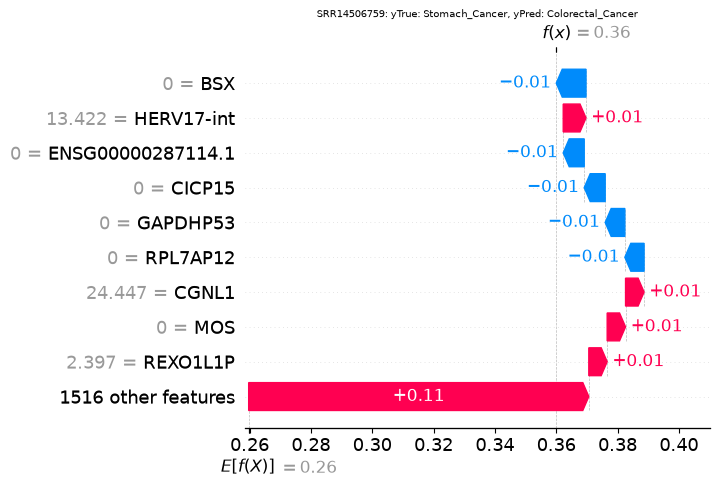

2026-10-21 12:57:57,263 WARNING 2301678336.py misclassified400BinaryDropHealthy_Lung() line:33] [FALSE POSITIVE]


data set : elifeMultiClassifierFrom400BinaryDropHealthyLung

SRR14506759
maxNumberOfFeaturesToDisplay:21
AEDWIP original title : SRR14506759: yTrue: Stomach_Cancer, yPred: Colorectal_Cancer


2026-10-21 12:57:58,125 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/explainedByColorectalModel_SRR14506759-yTrue-Stomach_Cancer-yPred-Colorectal_Cancer.png]
2026-10-21 12:57:58,526 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/explainedByColorectalModel_SRR14506759-yTrue-Stomach_Cancer-yPred-Colorectal_Cancer.pdf]


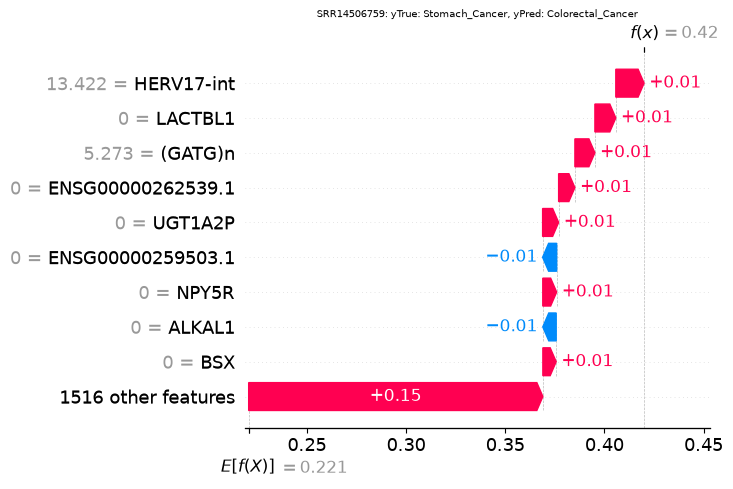

In [38]:
def misclassified400BinaryDropHealthy_Lung() -> list[plt.figure]:
    ''' 
    create waterfall plots for manuscript figure Figure F_R7_2
    
    returns a list with 2 figures. 
        subplot "c"
            Sample SRR145769 is misclassified stomach cancer sample explained by the stomach cancer classifier,
        
        subplot "d"
        Sample SRR145769 is misclassified stomach cancer sample explained by the 
        colorectal cancer classifier, illustrating why the sample was instead assigned to the colorectal class
    '''
                                            
    if dataSrcRunConfig_G.dataSetName != "elifeMultiClassifierFrom400BinaryDropHealthyLung" :
        logger.warning(f'skipping misclassified400BinaryDropHealthy_Lung() it only works for elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G')
        return 
    # find stomach samples miss classified as Lung
    #aedwipWaterfallPlots(stomachAsLungSampleIds, 'Lung_Cancer', errorXDF, errorExplanation)

    # candidate stomach FN with lung FP that is slightly higher
    # aedwipWaterfallPlots(['SRR14506759', 'SRR14506787', 'SRR14506778'], 'Stomach_Cancer', errorXDF, )

    # false negative stomach sample : explain using  stomach model 
    # aedwipWaterfallPlots(['SRR14506759'], 'Stomach_Cancer', errorDF, errorXDF, errorExplanation, geneMapDict=geneMapDict)
    SRR14506759StomachFigList = aedwipWaterfallPlots(['SRR14506759'], 'Stomach_Cancer', errorDF, errorXDF, errorExplanation, geneMapDict)

    # false positive
    #aedwipWaterfallPlots(['SRR14506759', 'SRR14506787', 'SRR14506778'], 'Lung_Cancer', errorXDF, errorExplanation)

    plt.show()
    
    # false positive
    logger.warning(f'FALSE POSITIVE')
    SRR14506759ColorectalFigList = aedwipWaterfallPlots(['SRR14506759'], 'Colorectal_Cancer', errorDF, errorXDF, errorExplanation, geneMapDict=geneMapDict)
    plt.show()
    plt.show()
    
    return SRR14506759StomachFigList + SRR14506759ColorectalFigList
    
    
if dataSrcRunConfig_G.dataSetName != "elifeMultiClassifierFrom400BinaryDropHealthyLung" :
    logger.warning(f'skipping displayPredictions400BinaryDropHealthy_LungDF it only works for elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G') 
else :
    waterFallFigList = misclassified400BinaryDropHealthy_Lung()

    waterfallLayout_G["c"].figure = waterFallFigList[0]
    waterfallLayout_G["d"].figure = waterFallFigList[1]
    

In [39]:
def manuscriptWaterfallPlots( sampleId : str,
                         diagnosis : str,
                         XDF : pd.DataFrame,
                        #  errorXDF : pd.DataFrame,
                        explanation : Explanation,
                        geneMapDict : dict[str, str] = None,
                         ) -> plt.figure:
    '''
    create and save water fall plots for samples using the 'diagnosis' model
    
    sample is explained using diganosis model and assumed to be a TRUE POSITIVE 
    
            geneMapDF :
                data frame returned by createEnsembleToHUGOMap()
                if not none, will be used to map ensemble ids to HUGO

        
    '''
    # logger.error(f'AEDWIP XDF.shape : {XDF.shape} XDF.iloc[0:3, 0:4] {XDF.iloc[0:3, 0:4]}')
        
    sampleIndexInShapValue = XDF.index.get_loc(sampleId)
    # logger.error(f'AEDWIP DO NOT HARD CODE 3')
    SHAPClassIdx = classToSHAPIndexDict[diagnosis]
    # logger.error(f'AEDWIP sampleIndexInShapValue : {sampleIndexInShapValue} SHAPClassIdx : {SHAPClassIdx}')
    sv = explanation[sampleIndexInShapValue, :, SHAPClassIdx]
    # logger.error(f'AEDWIP type(sv) : {type(sv)} sv.shape : {sv.shape}')
    
    if geneMapDict :
        sv = copy.deepcopy(sv)
        sv.feature_names = [ geneMapDict.get(featureName, featureName)
                                for featureName in sv.feature_names
                            ]

    yTrue = diagnosis # errorDF.loc[sampleId,'yTrue']
    yPred = diagnosis # errorDF.loc[sampleId,'yPred']
    title = f"{sampleId}: yTrue: {yTrue}, yPred: {yPred}"
    logger.error(f'AEDWIP title : {title}')
    
    # aedwip colorectal title might be to long? use long title for file name short for display
    # in panel we will remove the thitle anyway


    # 10/12/26 create nat bio med eng final artwork complient
    # previously we displayed all "meaning features". The plots are to big
    # only plot the top 10.

    maxNumberOfFeaturesToDisplay = chooseMaxDisplayByTolerance(sv.values) 
    print(f'maxNumberOfFeaturesToDisplay:{maxNumberOfFeaturesToDisplay}')
    fig = plotWaterfall(
            sv=sv, 
            width=7, # title is long 
            title=title,
            # maxNumberOfFeaturesToDisplay=maxNumberOfFeaturesToDisplay
            maxNumberOfFeaturesToDisplay=10
            )
    
    k = diagnosis.split('_')[0] # example Lung
    prefix = f'explainedBy{k}Model'
    saveFigure(fig, title, imgOutDir, prefix)
    
    return fig

# <span style="color:red;background-color:yellow;">True Positive, happy case plots</span>

In [40]:
topStomachSampleProbsDF = findTopSamplesForDiagnosis('Stomach_Cancer')
topStomachSampleProbsDF.sort_values(by='Stomach_Cancer', ascending=False).head()

sum(isDiagnosis) : 36
DF.shape : (36, 1525)


,Colorectal_Cancer,Esophagus_Cancer,Liver_Cancer,Stomach_Cancer,total
sampleIds,,,,,
SRR14506763,0.15,0.25,0.07,0.53,1.0
SRR14506768,0.17,0.21,0.10,0.52,1.0
SRR14506769,0.12,0.36,0.03,0.49,1.0
SRR14506766,0.31,0.13,0.07,0.49,1.0
SRR14506764,0.16,0.34,0.02,0.48,1.0


In [41]:
topColorectalSampleProbsDF = findTopSamplesForDiagnosis('Colorectal_Cancer')
topColorectalSampleProbsDF

sum(isDiagnosis) : 53
DF.shape : (53, 1525)


,Colorectal_Cancer,Esophagus_Cancer,Liver_Cancer,Stomach_Cancer,total
sampleIds,,,,,
SRR14506799,0.64,0.15,0.11,0.10,1.0
SRR14506812,0.55,0.19,0.02,0.24,1.0
SRR14506830,0.48,0.20,0.03,0.29,1.0
SRR14506800,0.47,0.17,0.34,0.02,1.0
SRR14506790,0.47,0.20,0.03,0.30,1.0


In [42]:
print(f'topStomachSampleProbsDF.shape : {topStomachSampleProbsDF.shape}')
print(f'topColorectalSampleProbsDF.shape : {topColorectalSampleProbsDF.shape}')


# topStomachSampleProbsDF = realXDF.loc[topStomachSampleProbsDF.index +  topColorectalSampleProbsDF.index, :]

stomachColorectalTPIndex = topStomachSampleProbsDF.index.append( topColorectalSampleProbsDF.index )

# stomachColorectalTP_XDF = pd.concat([topStomachSampleProbsDF, topColorectalSampleProbsDF])
stomachColorectalTP_XDF = realXDF.loc[stomachColorectalTPIndex, :]
print(f'stomachColorectalTP_XDF.shape : {stomachColorectalTP_XDF.shape}')


topStomachSampleProbsDF.shape : (5, 5)
topColorectalSampleProbsDF.shape : (5, 5)
stomachColorectalTP_XDF.shape : (10, 1525)


In [43]:
shapeCacheDir = f'/scratch/aedavids/fagazi/SHAP/{notebookName}/{dataSrcRunConfig_G.dataSetName}/TP'
os.makedirs(shapeCacheDir,  exist_ok=True)
stomachColorectalTP_ExplanationPath = f'{shapeCacheDir}/StomachColorectalTruePositiveExplanation.pkl'
stomachColorectalTPExplanation = getSHAPValues(
                        pklPath=stomachColorectalTP_ExplanationPath,
                        XDF=stomachColorectalTP_XDF,
                        explainer=treeInterventionalExplainer
                    )

2026-10-21 12:57:58,912 WARNING shapUtilities.py getSHAPValues() line:365] [loading : /scratch/aedavids/fagazi/SHAP/multiClassifierXAI_manuscript/elifeMultiClassifierFrom400BinaryDropHealthyLung/TP/StomachColorectalTruePositiveExplanation.pkl]


2026-10-21 12:57:58,947 ERROR 2338213074.py manuscriptWaterfallPlots() line:37] [AEDWIP title : SRR14506763: yTrue: Stomach_Cancer, yPred: Stomach_Cancer]


maxNumberOfFeaturesToDisplay:23


2026-10-21 12:57:59,937 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/explainedByStomachModel_SRR14506763-yTrue-Stomach_Cancer-yPred-Stomach_Cancer.png]
2026-10-21 12:58:00,617 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/explainedByStomachModel_SRR14506763-yTrue-Stomach_Cancer-yPred-Stomach_Cancer.pdf]


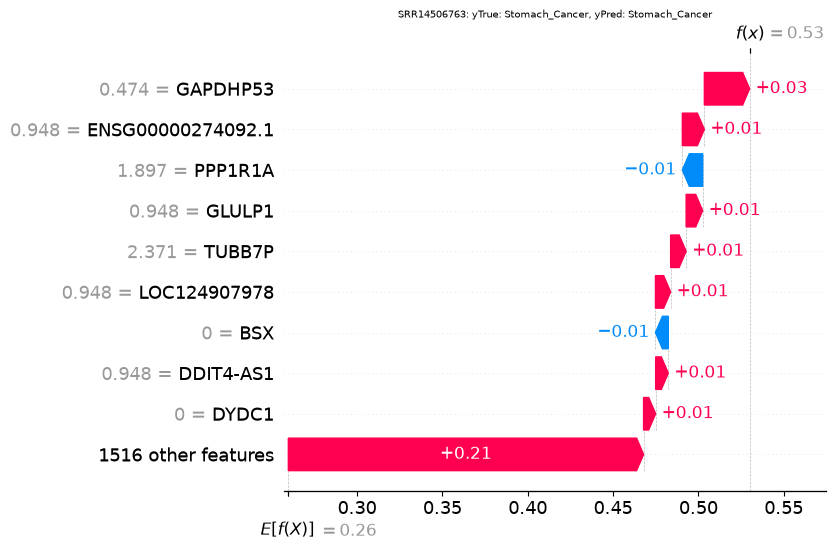

In [44]:
# True Positive
figSubplot_A = manuscriptWaterfallPlots('SRR14506763', 'Stomach_Cancer', 
                         stomachColorectalTP_XDF, stomachColorectalTPExplanation, geneMapDict)
plt.show()

waterfallLayout_G["a"].figure = figSubplot_A

2026-10-21 12:58:00,921 ERROR 2338213074.py manuscriptWaterfallPlots() line:37] [AEDWIP title : SRR14506799: yTrue: Colorectal_Cancer, yPred: Colorectal_Cancer]


maxNumberOfFeaturesToDisplay:21


2026-10-21 12:58:01,865 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/explainedByColorectalModel_SRR14506799-yTrue-Colorectal_Cancer-yPred-Colorectal_Cancer.png]
2026-10-21 12:58:02,205 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/explainedByColorectalModel_SRR14506799-yTrue-Colorectal_Cancer-yPred-Colorectal_Cancer.pdf]


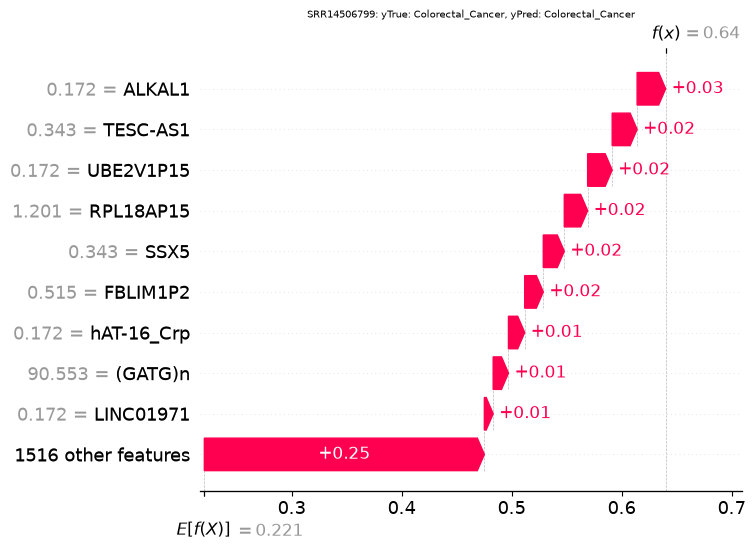

In [45]:
# TRUE positive

figSubplot_b = manuscriptWaterfallPlots('SRR14506799', 'Colorectal_Cancer', 
                         stomachColorectalTP_XDF, stomachColorectalTPExplanation, geneMapDict)
plt.show()

waterfallLayout_G["b"].figure = figSubplot_b

In [46]:
# from matplotlib.text import Text
# from pymupdf import f

from matplotlib.transforms import ScaledTranslation
from matplotlib.backends.backend_agg import FigureCanvasAgg


def fixWaterfallLabelSpacing(fig, gapPt: float = 1.5):
    """
    Close gaps in SHAP's split E[f(X)] and f(x) labels.
    caused by change in font size
    
    generated by chatGPT
    """

    # fig.canvas.draw()
    # renderer = fig.canvas.get_renderer()
    

    if not hasattr(fig.canvas, "get_renderer"):
        FigureCanvasAgg(fig)  # Attach a canvas that can measure text.

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    for ax in fig.axes:
        labels = [
            label for label in ax.get_xticklabels()
            if label.get_visible() and label.get_text().strip()
        ]

        # SHAP uses a separate two-label axis for each expression.
        if len(labels) != 2:
            continue

        expression, value = labels

        if (
            "f(" not in expression.get_text()
            or "=" not in value.get_text()
        ):
            continue

        expressionBox = expression.get_window_extent(renderer)
        valueBox = value.get_window_extent(renderer)

        gapPixels = gapPt * fig.dpi / 72
        shiftPixels = expressionBox.x1 + gapPixels - valueBox.x0

        value.set_transform(
            value.get_transform()
            + ScaledTranslation(
                shiftPixels / fig.dpi,
                0,
                fig.dpi_scale_trans,
            )
        )
        


In [47]:

def createWaterfallPlotFinalArtwork(
                                    panelConfig : dict[str, Panel],
                                    panelId : str, 
                                    newSampleId : str = None, 
                                    fontSize : int = 7,
                                    ) -> plt.figure:
    ''' 
    re-works figure so that it is complient
    
    https://www.nature.com/documents/NRJs-guide-to-preparing-final-artwork.pdf
    
    arguments : 
        newSampleId : 
            Daniel suggested we simplify the names to make it easier to compare
            the same sample in multiple subplots
            
            example of an original sample id 'SRR14506763'
    '''
    # set default matplotlib style defaults
    with plt.rc_context(natureManuscriptStyle):
        print("begin")
        fig = panelConfig[panelId].figure
        if not fig :
            logger.warning(f'panelId : {panelId} figure was None')
            return None
        
        print( f'fig size in inches : {fig.get_size_inches()}' )
        print( f'fig size in mm : {fig.get_size_inches() * 25.4}' )
        
        widthInMM, heightInMM =  getSubplotWidthAndHeight(panelConfig, panelId)
        
        # resize the figure
        fig.set_size_inches(widthInMM / 25.4, heightInMM / 25.4)

        # set the font size
        # Class names, axis labels, and title.
        print(f'len(fig.get_axes()) : {len(fig.get_axes())}')
        
        i = 0
        for ax in fig.get_axes() : 
            title = ax.get_title()
            # print(f'ax i: {i} title : {title}')
            # i = i+1

            # there are three axes.
            # the main one is the actual water fall
            # there is one on top for f(x)
            # another axes on bottom for E[f(x)]
            ax.tick_params(axis="both", labelsize=fontSize)
            ax.xaxis.label.set_fontsize(fontSize)
            ax.yaxis.label.set_fontsize(fontSize)
            ax.title.set_fontsize(fontSize)
            
            legend = ax.get_legend()
            if legend is not None:
                for text in legend.get_texts():
                    text.set_fontsize(fontSize) 
                legend.get_title().set_fontsize(fontSize)   
                
        # change the font size of the numeric values in the main body of the plot
        for textArtist in fig.findobj(match=Text):
            textArtist.set_fontsize(fontSize) 
            
        # what is the size of each axes, can we resent the title?
        for i, fooAx in enumerate(fig.get_axes()):
            pos = fooAx.get_position()
            print(f'AEDWIP i : {i} : pos : {pos}')
            
        # change title
        # yTrue -> True
        # yPred -> predicted
        titleAx = fig.get_axes()[2]
        print(f'titleAx.get_title() : {titleAx.get_title()}')
        newTitle = (
            titleAx.get_title()
            .replace("yTrue:", "true:")
            .replace("yPred:", "predicted:")
            .replace("_", " ")
            # .replace("Cancer", "cancer")
            .strip()
            .lower() # convert the entire title to lower case
            #.capitalize() # capitalize the first word in titel
            .replace("sample", "Sample")

        )
        titleAx.set_title( newTitle )
        
        if newSampleId : 
            # change the title's sample id
            originalTitle = fig.get_axes()[2].get_title()
            print(f'original title : {originalTitle}')
            
            tokens = originalTitle.split(":")
            print(f'tokens : {tokens}')
            newTokens = [newSampleId] + tokens[1:]
            newTitle = ":".join(newTokens)
            fig.get_axes()[2].set_title(newTitle, fontsize=fontSize )
            print(f'new title : {newTitle}')

        
        print( f'fig size in inches : {fig.get_size_inches()}' )
        print( f'fig size in mm : {fig.get_size_inches() * 25.4}' )
            
        # Move the existing axes title to the center of the subplot canvas.
        titleAx = next(
            (ax for ax in fig.axes if ax.get_title()),
            None,
        )

        # Use the complete title we just constructed.
        print(f"title being centered: {newTitle!r}")

        for ax in fig.axes:
            ax.set_title("")

        fig.suptitle(
            newTitle,
            x=0.5,
            y=0.98,
            ha="center",
            fontsize=fontSize,
            fontfamily="Arial",
        )
        
        # 10/19/26
        # Daniel's suggestion:
        # add an x-axis to explain what ticks mean
        # in particular how are "c" and "d" different
        
        explainedClass = {
        "a": "stomach",
        "b": "colorectal",
        "c": "stomach",
        "d": "colorectal",
        }

        ax = fig.axes[0]
        ax.set_xlabel(
            f"Predicted {explainedClass[panelId]} cancer probability",
            fontsize=6,
            #labelpad=22,
            labelpad=10,
        )
        

        # change the font family to "Arial"
        setFigureFont(fig)
            
        # # Reserve the top portion of the canvas for the title.
        fig.tight_layout(rect=(0, 0, 1, 0.92))
        
        # fig.tight_layout()
    
        print("end")

    return fig

In [48]:
if dataSrcRunConfig_G.dataSetName != "elifeMultiClassifierFrom400BinaryDropHealthyLung" :
    logger.warning(f'skipping displayPredictions400BinaryDropHealthy_LungDF it only works for elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G') 
else :
    # this messes up the final panel
    # testFig = createWaterfallPlotFinalArtwork(waterfallLayout_G,
    #                                         "c",
    #                                         newSampleId="aedwipxxx"
    #                                         )

    # display(testFig)
    pass

## <span style="color:red;background-color:yellow;">10/13/26 create waterfall final artwork fig</span>

In [49]:
def displayPredictions400BinaryDropHealthy_LungDF() -> plt.figure:
    '''
    this only works with data set elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G
    '''
    if dataSrcRunConfig_G.dataSetName != "elifeMultiClassifierFrom400BinaryDropHealthyLung" :
        logger.warning(f'skipping displayPredictions400BinaryDropHealthy_LungDF it only works for elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G')
        return 
    
    # predictions for samples of interest
    # display(topStomachSampleProbsDF)
    # display(topColorectalSampleProbsDF)


    predictionDF = pd.concat( [
                topStomachSampleProbsDF.loc['SRR14506763', :], # stomach exp p = 0.53
                topColorectalSampleProbsDF.loc['SRR14506799', :], # col exp p = 0.64
                checkStomachPredictions400BinaryDropHealthy_LungDF.loc['SRR14506759', :], # col exp p = 0.42 #mis classification error
                
                # SRR14506759 stomach explained by stomach p = 0.36
            ], axis=1).transpose()  

    predictionDF['diagnosis'] = ['Stomach_Cancer',  'Colorectal_Cancer', 'Stomach_Cancer',]

    # predictionDF['explainer'] = ['Stomach_Cancer','Colorectal_Cancer', 'Colorectal_Cancer']

    predictionDF = predictionDF.loc[:, ['diagnosis', 'Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer', 'Stomach_Cancer', 'total']]

    display( predictionDF )

    outPath = f'{imgOutDir}/samplePredictionDataFrame.png'
    fig = saveDataFrameImage(predictionDF, outPath)
    
    return fig

,diagnosis,Colorectal_Cancer,Esophagus_Cancer,Liver_Cancer,Stomach_Cancer,total
SRR14506763,Stomach_Cancer,0.15,0.25,0.07,0.53,1.0
SRR14506799,Colorectal_Cancer,0.64,0.15,0.11,0.10,1.0
SRR14506759,Stomach_Cancer,0.42,0.19,0.03,0.36,1.0


2026-10-21 12:58:02,757 WARNING plotUtilities.py saveDataFrameImage() line:204] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/samplePredictionDataFrame.png]
2026-10-21 12:58:02,926 WARNING plotUtilities.py saveDataFrameImage() line:207] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/samplePredictionDataFrame.pdf]


layout[e].widthMm : 180
layout[e].heightMm : 19
 oldSampleIds : ['SRR14506763', 'SRR14506799', 'SRR14506759']
dict_keys(['SRR14506763', 'SRR14506799', 'SRR14506759'])
xxxoldSampleIdxxx : xxxSRR14506763xxx
dict_keys(['SRR14506763', 'SRR14506799', 'SRR14506759'])
xxxoldSampleIdxxx : xxxSRR14506799xxx
dict_keys(['SRR14506763', 'SRR14506799', 'SRR14506759'])
xxxoldSampleIdxxx : xxxSRR14506759xxx


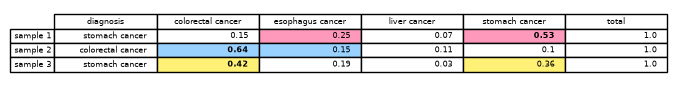

In [50]:
def displayPredictions400BinaryFinalArtwork(
        fontSize : int = 7
    ):
    
    if dataSrcRunConfig_G.dataSetName != "elifeMultiClassifierFrom400BinaryDropHealthyLung" :
        logger.warning(f'skipping displayPredictions400BinaryFinalArtwork() it only works for elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G')
        return 
    
    # set default matplotlib style defaults
    with plt.rc_context(natureManuscriptStyle):
            fig = displayPredictions400BinaryDropHealthy_LungDF()
            # display(fig)
            
            # change the font family
            setFigureFont(fig)
            
            # Apply your existing layout adjustment here.
            panelId = "e"
            widthInMM, heightInMM =  getSubplotWidthAndHeight(waterfallLayout_G, panelId)
            fig.set_size_inches(widthInMM / 25.4, heightInMM / 25.4)
            ax = fig.get_axes()[0]

            # change the sample ids
            table = ax.tables[0]
            
            # stomach_cancer -> stomach cancer
            for cell in table.get_celld().values():
                text = cell.get_text()
                text.set_text(text.get_text().replace("_", " "))


            # list comprehension
            oldSampleIds = [
                cell.get_text().get_text()
                for (row, col), cell in sorted(table.get_celld().items())
                if col == -1 #0 is the diagnosis column
            ]
            print(f' oldSampleIds : {oldSampleIds}')
            for i, oldSampleId in enumerate(oldSampleIds):
                print(waterfallSampleMap2Dict.keys())
                print(f'xxxoldSampleIdxxx : xxx{oldSampleId}xxx')
                newSampleId = waterfallSampleMap2Dict[ oldSampleId ]
                if newSampleId :
                    cell = table[i + 1, -1]
                    cell.get_text().set_text(newSampleId)
                    
                    
            # highlight cells to emphasise Prediction margins
            cellsToHighlight = [
                                (1, 2), (1, 4), # stomach predicted to be stomach
                                (2, 1), (2, 2), # colorectal predicted to be colorectal
                                (3, 1), (3, 4) # misclassifcation
                                ]

            rowColors = {
                # 1: "#DEEBF7",  # Pale blue
                # 2: "#E8E1F2",  # Pale lavender
                # 3: "#FBE5D6",  # Pale peach
                # 1: "#FFF176",  # Highlighter yellow
                # 2: "#B9F6A5",  # Highlighter green
                # 3: "#FFADD6",  # Highlighter pink
                1: "#FF99BB",  # Light version of SHAP pink-red
                2: "#99D1FF",  # Light version of SHAP blue
                3: "#FFF176",  # Highlighter yellow
            }
            
            # Highest-probability cell in each row.
            predictedCells = {(1, 4), (2, 1), (3, 1)}

            for row, col in cellsToHighlight:
                cell = table[row, col]
                cell.set_facecolor(rowColors[row])
                cell.get_text().set_color("black")
                cell.get_text().set_fontweight(
                    "bold" if (row, col) in predictedCells else "normal"
                )
                
            # all the indices, and headers should be lower case
            for cell in table.get_celld().values():
                text = cell.get_text()
                text.set_text(text.get_text().lower())
            
            # change font sizes
            legend = ax.get_legend()
            if legend is not None:
                for text in legend.get_texts():
                    text.set_fontsize(fontSize) 
                legend.get_title().set_fontsize(fontSize)   
                
                
            # change the font size of the numeric values in the main body of the plot
            # Disable automatic font shrinking in any tables.
            for ax in fig.axes:
                for table in ax.tables:
                    table.auto_set_font_size(False)
                    table.set_fontsize(fontSize)
                    
            # Set the size of all existing Matplotlib text.
            for textArtist in fig.findobj(match=Text):
                textArtist.set_fontsize(fontSize) 
            
            waterfallLayout_G[panelId].figure = fig
            
            # fixWaterfallLabelSpacing(fig)

            display(fig)
            
            
displayPredictions400BinaryFinalArtwork(fontSize=6)


In [51]:
def plotWaterfallLegend(
    widthMm: float = 180,
    heightMm: float = 12,
    fontSize: float = 7,
) -> Figure:
    """Create a centered explanatory key for panels a–e."""

    # lines = [
    #     "a–d: X-axis: predicted probability of the explained class. "
    #     "E[f(X)]: mean over SHAP background samples; f(x): sample probability.",

    #     "Red / blue arrows: positive / negative SHAP contributions; "
    #     "arrow numbers show contribution values. "
    #     "Values before feature names: normalized transcript counts.",

    #     "e: Shading pairs the two highest probabilities per sample; "
    #     "bold: highest. Their difference is the prediction margin.",

    #     "Smaller margins indicate closer competing predictions.",
    # ]

    lines = [
        "a–d: X-axis: predicted probability of the explained class. "
        "E[f(X)]: baseline probability; f(x): sample probability.",

        "Red / blue arrows: positive / negative SHAP contributions. "
        "Arrow numbers: contribution values; values before feature names: normalized transcript counts.",

        "c–d: Same stomach cancer sample, misclassified as colorectal. "
        "c explains the Stomach probability; d explains the Colorectal probability.",

        "e: Shading pairs the two highest probabilities per sample; bold: highest. "
        "Prediction margin: their difference; smaller margins indicate closer predictions.",
    ]
    
    fig = plt.figure(
        figsize=(widthMm / 25.4, heightMm / 25.4),
        layout="none",
        facecolor="white",
    )

    # Extra separation between the a–d and e explanations.
    for y, line in zip((0.88, 0.65, 0.35, 0.12), lines):
        fig.text(
            0.5,
            y,
            line,
            ha="center",
            va="center",
            fontfamily="Arial",
            fontsize=fontSize,
            color="black",
        )

    return fig

2026-10-21 12:58:03,131 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,137 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,138 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,139 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,140 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,141 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,142 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,143 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]



**** 
panelId : a idTuple : ('SRR145763', 'Sample 1')
begin
fig size in inches : [7.     5.6875]
fig size in mm : [177.8    144.4625]
layout[a].widthMm : 90
layout[a].heightMm : 76
len(fig.get_axes()) : 3
AEDWIP i : 0 : pos : Bbox(x0=0.125, y0=0.10999999999999999, x1=0.9, y1=0.88)
AEDWIP i : 1 : pos : Bbox(x0=0.125, y0=0.10999999999999999, x1=0.9, y1=0.88)
AEDWIP i : 2 : pos : Bbox(x0=0.125, y0=0.10999999999999999, x1=0.9, y1=0.88)
titleAx.get_title() : SRR14506763: yTrue: Stomach_Cancer, yPred: Stomach_Cancer
original title : srr14506763: true: stomach cancer, predicted: stomach cancer
tokens : ['srr14506763', ' true', ' stomach cancer, predicted', ' stomach cancer']
new title : Sample 1: true: stomach cancer, predicted: stomach cancer
fig size in inches : [3.54330709 2.99212598]
fig size in mm : [90. 76.]
title being centered: 'Sample 1: true: stomach cancer, predicted: stomach cancer'


2026-10-21 12:58:03,150 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,151 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,152 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,153 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,154 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,155 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,156 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,159 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


end


2026-10-21 12:58:03,595 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,598 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,599 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,600 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,606 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,607 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,608 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:03,609 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]



**** 
panelId : b idTuple : ('SRR145799', 'Sample 2')
begin
fig size in inches : [7.     5.6875]
fig size in mm : [177.8    144.4625]
layout[b].widthMm : 90
layout[b].heightMm : 76
len(fig.get_axes()) : 3
AEDWIP i : 0 : pos : Bbox(x0=0.125, y0=0.10999999999999999, x1=0.9, y1=0.88)
AEDWIP i : 1 : pos : Bbox(x0=0.125, y0=0.10999999999999999, x1=0.9, y1=0.88)
AEDWIP i : 2 : pos : Bbox(x0=0.125, y0=0.10999999999999999, x1=0.9, y1=0.88)
titleAx.get_title() : SRR14506799: yTrue: Colorectal_Cancer, yPred: Colorectal_Cancer
original title : srr14506799: true: colorectal cancer, predicted: colorectal cancer
tokens : ['srr14506799', ' true', ' colorectal cancer, predicted', ' colorectal cancer']
new title : Sample 2: true: colorectal cancer, predicted: colorectal cancer
fig size in inches : [3.54330709 2.99212598]
fig size in mm : [90. 76.]
title being centered: 'Sample 2: true: colorectal cancer, predicted: colorectal cancer'


... (9 outputs left out)

end


2026-10-21 12:58:05,520 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,522 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,524 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,526 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,527 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,531 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,532 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,533 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


Layout valid: 180 × 173 mm total; panels occupy extents of 180 × 173 mm.


2026-10-21 12:58:05,835 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,836 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,836 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,837 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,838 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,839 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,840 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-10-21 12:58:05,841 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


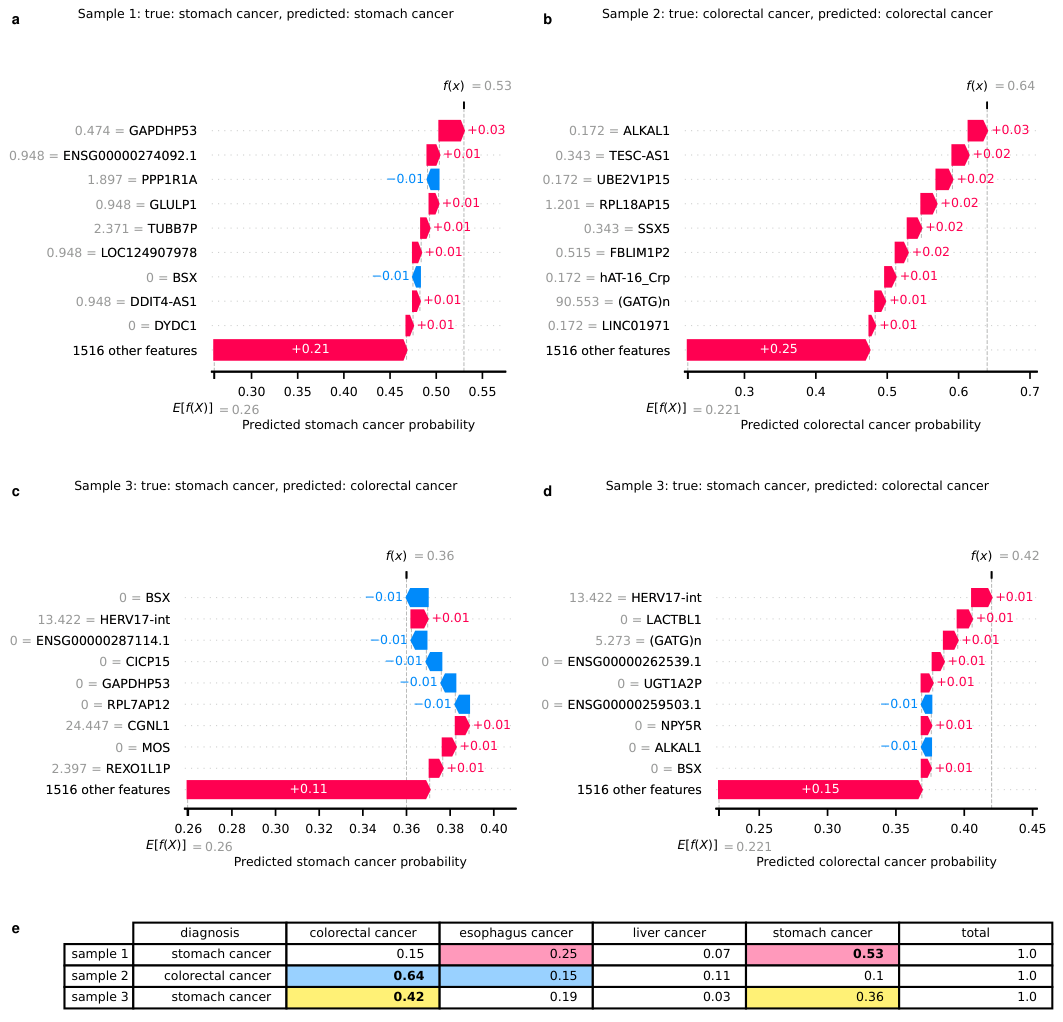

2026-10-21 12:58:09,174 WARNING 749648686.py createWaterFallFinalArtworkFig() line:43] [save : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/manuscript/F_R7_2_waterfallPanel.pdf ]


In [52]:
def createWaterFallFinalArtworkFig():
    if dataSrcRunConfig_G.dataSetName != "elifeMultiClassifierFrom400BinaryDropHealthyLung" :
        logger.warning(f'skipping displayPredictions400BinaryDropHealthy_LungDF it only works for elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G')
        return     
       
    # for panelId in waterfallLayout_G.keys():
    waterFallPlotPanelIds = ["a", "b", "c", "d"]
    # "e" is table
    for panelId in waterFallPlotPanelIds:
        newSampleId = None
        idTuple = waterfallSampleIdMappingDict.get(panelId, None)
        if idTuple :
            originalId, newSampleId = idTuple
        print(f'\n**** ')
        print(f'panelId : {panelId} idTuple : {idTuple}')
        
        # we do not need to keep track of the returned figs
        # we modifed the figs in waterfallLayout_G
        fig = createWaterfallPlotFinalArtwork(waterfallLayout_G,
                                        panelId,
                                        newSampleId,
                                        fontSize=6
                                          )
        fixWaterfallLabelSpacing(fig)
        
        
    # legendFig = plotWaterfallLegend(fontSize=7)
        
    logger.error(f'AEDWIP TODO add legend')
    waterfallOstem = Path(f'{imgOutDir}/manuscript/F_R7_2_waterfallPanel') 
    waterfallOstem.mkdir(parents=True, exist_ok=True)

    pdfPath, pngPath = combineFiguresLayout(
        panels=waterfallLayout_G,
        outputStem=waterfallOstem,
        widthMm=180,
        heightMm=173,       # Data area only.
        legendFigure=None,#legendFig,
        legendHeightMm=0, #12,  # Added below: total height = 185 mm.
    )

    displayPDFInNotebook( pdfPath )
    logger.warning(f'save : {pdfPath} ')
    
createWaterFallFinalArtworkFig()

# <span style="color:red;background-color:yellow;">Random Forest feature importance</span>
model.feature_importances_ is global. It is calcuated from the splits durring training. We can explain our real data using this.

it is the normalized total decrease in node impurity attributed to each feature across all trees. It is also called mean decrease in impurity or Gini importance.

That is a useful model-level global explanation, but it does not tell you:
- which class a feature supports;
- whether high expression increases or decreases a class probability;
- whether the feature remains important on real samples.

Impurity importance can be misleading because it can favor features with many possible split points. Scikit-learn recommends permutation importance as an alternative

**understanding impurity based plots***.  
The x-axis shows the reduction in gini impurity. It is unitless. 

meaning : Fraction of the forest's total impurity reduction attributed to the feature. The numbers have been normalized, if the plot shows Gene_A 0.18 It means Gene A accounted for 18% of the total impurity reduction produced by all trees in the forest.

In [53]:
def getRandomForestImportanceDF(
        model: Any,
        featureNames: list[str]
    ) -> pd.DataFrame:
    """
    Return impurity-based random-forest feature importance.
    """

    importanceDF = pd.DataFrame({
        "feature": featureNames,
        "importance": model.feature_importances_
    })

    importanceDF = (
        importanceDF
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

    importanceDF["rank"] = np.arange(
        1,
        len(importanceDF) + 1
    )

    return importanceDF


importanceDF = getRandomForestImportanceDF(
    model=model,
    featureNames=list(model.feature_names_in_)
)

In [54]:
# def changeYlabels(geneMapDict, ax) -> None:
#     '''
#     aedwip
    
#     '''
#     # yLabels = list([label.get_text() for label in ax.get_yticklabels()])
#     yTicks = ax.get_yticks()
#     yLabels = [label.get_text() for label in ax.get_yticklabels()]
#     logger.debug(f'AEDWIP yLables {list(yLabels)}')
    
#     newYLabels = [geneMapDict[label] for label in yLabels]
#     logger.debug(f'AEDWIP yLables {list(newYLabels)}')

#     ax.set_yticks( yTicks )
#     ax.set_yticklabels(list(newYLabels))

2026-10-21 12:58:09,855 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/_Global-feature-importance-for-multiclass-classification.png]
2026-10-21 12:58:10,160 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/_Global-feature-importance-for-multiclass-classification.pdf]


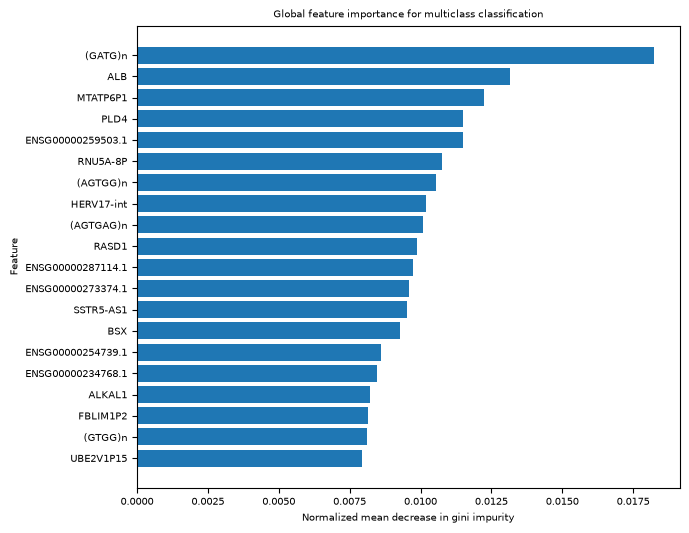

In [55]:
def plotRandomForestImportance(
        importanceDF: pd.DataFrame,
        maxDisplay: int = 20,
        geneMapDict : dict[str, str] = None, 
    ) -> tuple[Figure, Axes]:
    """
    Ranked global random forest importance
    Plot top random-forest impurity-based feature importances.
    
    arguments:
        geneMapDict :
            default None
            if geneMapDict
                use geneMapDict to replace ytick labels
    """

    plotDF = (
        importanceDF
        .head(maxDisplay)
        .sort_values("importance", ascending=True)
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    ax.barh(
        plotDF["feature"],
        plotDF["importance"]
    )

    # ax.set_xlabel("Random forest feature importance")
    ax.set_xlabel('Normalized mean decrease in gini impurity')
    ax.set_ylabel("Feature")
    ax.set_title(
        "Global feature importance for multiclass classification"
    )
    
    if geneMapDict :
        changeYlabels(geneMapDict, ax)

    # plt.tight_layout()
    # plt.show()
    
    return (fig, ax)


rfFeatureImportanceFig,rfFeatureImportanceAxes = plotRandomForestImportance(
    importanceDF=importanceDF,
    maxDisplay=20, 
    geneMapDict=geneMapDict,
)

saveFigure(rfFeatureImportanceFig, rfFeatureImportanceAxes.get_title(), outDirArg=imgOutDir)
plt.show()


In [56]:
def getRandomForestImportanceWithSD(
        model: Any,
        featureNames: list[str], 
    ) -> pd.DataFrame:
    """
    Calculate mean and standard deviation of impurity importance
    across trees.
    """

    treeImportanceMatrix = np.asarray([
        tree.feature_importances_
        for tree in model.estimators_
    ])

    importanceDF = pd.DataFrame({
        "feature": featureNames,
        "importance": treeImportanceMatrix.mean(axis=0),
        "importanceSD": treeImportanceMatrix.std(axis=0)
    })

    return (
        importanceDF
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )


2026-10-21 12:58:11,004 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/_SD-Global-feature-importance-for-multiclass-classification.png]
2026-10-21 12:58:11,304 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/_SD-Global-feature-importance-for-multiclass-classification.pdf]


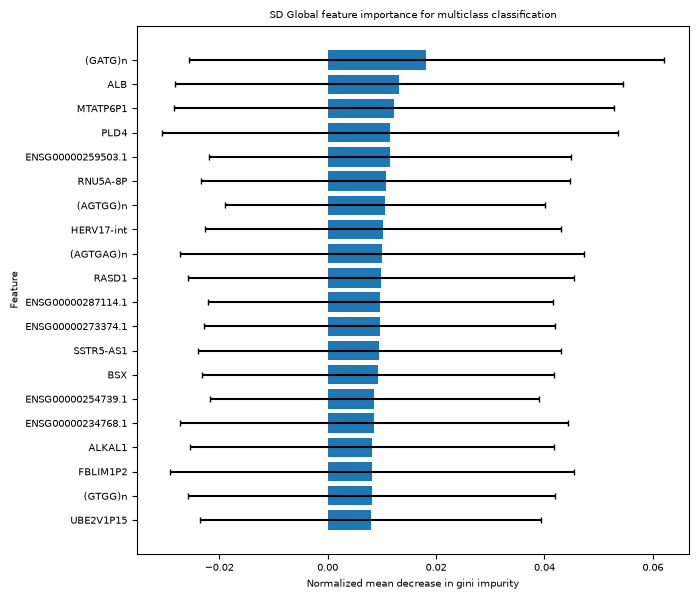

In [57]:
def plotRandomForestImportanceWithErrorBars (
            model: Any,
            geneMapDict : dict[str, str] = None
    ) -> tuple[Figure, Axes]:
    ''' 
    Ranked global random forest importance
    Plot top random-forest impurity-based feature importances.
    
    geneMapDict :
        default None
        if geneMapDict
            use geneMapDict to replace ytick labels
    '''
    
    importanceSD_DF = getRandomForestImportanceWithSD(
        model=model,
        featureNames=list(model.feature_names_in_)
    )

    plotDF = (
        importanceSD_DF
        .head(20)
        .sort_values("importance", ascending=True)
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    ax.barh(
        plotDF["feature"],
        plotDF["importance"],
        xerr=plotDF["importanceSD"],
        capsize=2
    )

    # ax.set_xlabel("Mean decrease in impurity")
    ax.set_xlabel('Normalized mean decrease in gini impurity')

    ax.set_ylabel("Feature")
    ax.set_title(
        "SD Global feature importance for multiclass classification"
    )
    
    if geneMapDict :
        changeYlabels(geneMapDict, ax)
        
    return(fig, ax)

rffi_ErrorBarsFig, rffi_ErrorBarsAxes = plotRandomForestImportanceWithErrorBars(model, geneMapDict)
saveFigure(rffi_ErrorBarsFig, rffi_ErrorBarsAxes.get_title(), outDirArg=imgOutDir)
plt.tight_layout()
plt.show()

<span style="color:red;background-color:yellow;">  Important limitation for your RNA data</span>

Impurity importance can be misleading because it can favor features with many possible split points. Scikit-learn recommends permutation importance as an alternative.

Because all of the features are normalized transcript counts, the high-cardinality problem may be more uniform than in a dataset mixing continuous, binary, and categorical variables. Nevertheless, your larger problem is likely correlated genes.

When several genes contain similar information:

one gene may be selected for a split;
nearby correlated genes may appear unimportant;
importance can be distributed unpredictably among correlated features.

Thus, the RF bar plot describes which features the fitted forest used, not necessarily every biologically relevant feature.

## <span style="color:red;background-color:yellow;">   calculate permutation importance on real sample</span>
How much does performance on real samples decrease when this feature is disrupted?

what do the units on the x-axis mean? If scoring=make_scorer(balanced_accuracy_score), and the original model had balance_accuracy of 0.82 and after permutation it dropped to 0.74 then Permutation importance = 0.82 - 0.74

Randomly destroying Gene A decreases balanced accuracy by 11 percentage points on average.

The **balanced accuracy** in binary and multiclass classification problems to deal with imbalanced datasets. It is **defined as the average of recall obtained on each class**. Recall == sensitivity == true positive rate

In [58]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, balanced_accuracy_score

def calculatePermutationImportance(
                model: Any,
                realXDF : pd.DataFrame,
                realYSeries : pd.Series,
                geneMapDict : dict[str, str] = None
    ) -> pd.DataFrame :
    ''' 
    use permutation to calculate feature importance on real samples
    
    scoring=make_scorer(balanced_accuracy_score)
    
    balanced accuracy classification problems to deal with imbalanced datasets. 
    It is defined as the average of recall obtained on each class.
    Recall == sensitivity == true positive rate
    
    # https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html
    
    arguments:
        geneMapDict :
        default None
        if geneMapDict
            use geneMapDict to replace ytick labels
    '''
    permutationResult = permutation_importance(
        estimator=model,
        X=realXDF,
        y=realYSeries,
        scoring=make_scorer(balanced_accuracy_score),
        n_repeats=50,
        random_state=42,
        n_jobs=-1
    )

    permutationImportanceDF = pd.DataFrame({
        "feature": model.feature_names_in_,
        "importanceMean": permutationResult.importances_mean,
        "importanceSD": permutationResult.importances_std
    })

    permutationImportanceDF = (
        permutationImportanceDF
        .sort_values("importanceMean", ascending=False)
        .reset_index(drop=True)
    )    
    
    return permutationImportanceDF


In [59]:
# I moved this out of createManuscriptFI() to make it faster to 
# debug making pixel perfect figure 
# it takes 1 min to run making pixel perfect figure 
finalPermutationImportanceDF= calculatePermutationImportance(model, realXDF, realYSeries, geneMapDict)


In [60]:

# def permutationImportance(
import matplotlib as mpl


def plotPermutationImportance(
        permutationImportanceDF : pd.DataFrame,
        widthInMM: float = 180,
        heightInMM: float = 120,
        geneMapDict: dict | None = None,
    ) -> tuple[Figure, Axes]:
    
    
    plotDF = (
        permutationImportanceDF
        .head(20)
        .sort_values("importanceMean", ascending=True)
    )


    # fig, ax = plt.subplots(figsize=(7, 6))
    with mpl.rc_context(dict(natureManuscriptStyle)):
        fig, ax = plt.subplots(figsize=(widthInMM / 25.4, heightInMM / 25.4))

        ax.barh(
            plotDF["feature"],
            plotDF["importanceMean"],
            xerr=plotDF["importanceSD"],
            height=0.7,
            color="#2A788E",
            capsize=2,
              error_kw={
                "ecolor": "black",
                "elinewidth": 0.7,
                "capthick": 0.7,
            },
        )

        # ax.axvline(0, linewidth=1)
        ax.axvline(
            0,
            color="0.4",
            linewidth=0.7,
            zorder=0,
        )

        # ax.set_xlabel(
        #     "Decrease in holdout balanced accuracy after permutation"
        # )
        
        # ax.set_ylabel("Feature")
        
        ax.set_xlabel("Decrease in balanced accuracy")
        ax.set_ylabel("")
        ax.set_title(
            "Feature importance evaluated on independent real samples"
        )
        
        if geneMapDict :
            changeYlabels(geneMapDict, ax)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        for spine in ax.spines.values():
            spine.set_linewidth(0.6)

        ax.tick_params(
            axis="both",
            which="both",
            width=0.6,
            length=3,
        )

        ax.margins(x=0.04, y=0.02)

        # Space for long feature names and the x-axis label.
        fig.subplots_adjust(
            left=0.27,
            right=0.98,
            bottom=0.12,
            top=0.98,
        )

    return (fig, ax)


## <span style="color:red;background-color:yellow;">10/20/26 create final artwork complient version of Extended Data Figure F_R7_1. Permutation feature importance evaluated on independent real holdout samples. </span>

**HERV17-int error bar crossing zero is not a plotting error.**  

importanceMean +- importanceSD

Its left endpoint is negative because the SD exceeds the positive mean.

Permutation importance is the original score minus the score after shuffling a feature. A negative value in an individual repeat means the shuffled data produced a higher score. If your columns come from scikit-learn, the SD measures variation across permutation repeats. scikit-learn 1.9.1 documentation

For HERV17-int, the positive mean indicates an average decrease in accuracy after shuffling, but the variation is large relative to that decrease. A mean ± SD interval crossing zero does not establish statistical nonsignificance, nor prove that any individual repeat was negative. Inspect the individual repeat values to determine that.

2026-10-21 12:59:21,173 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/_Feature-importance-evaluated-on-independent-real-samples_ExD-Figure_F_R7_1.png]
2026-10-21 12:59:21,392 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/_Feature-importance-evaluated-on-independent-real-samples_ExD-Figure_F_R7_1.pdf]


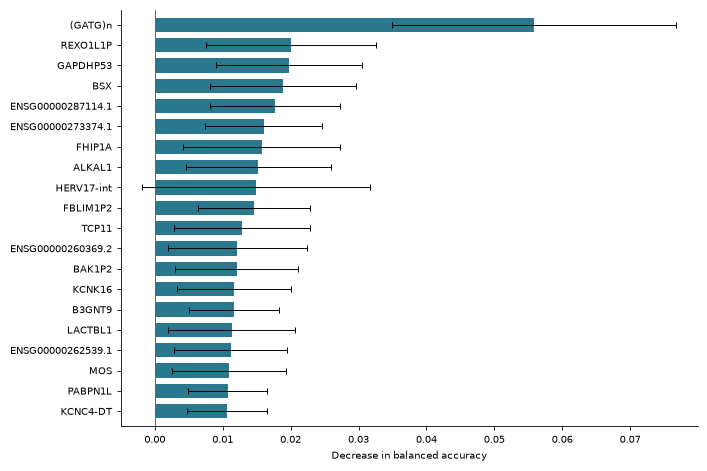

In [61]:
def createManuscriptFI():
    # if dataSrcRunConfig_G.dataSetName != "elifeMultiClassifierFrom400BinaryDropHealthyLung" :
    #     logger.warning(f'skipping misclassified400BinaryDropHealthy_Lung() it only works for elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G')
    #     return 

    # permutationImportanceFig, permutationImportanceAx = permutationImportance(model, realXDF, realYSeries, geneMapDict)
    permutationImportanceFig, permutationImportanceAx = plotPermutationImportance( 
                                                                                  finalPermutationImportanceDF,
                                                                                  geneMapDict=geneMapDict)

    # keep old file path for backwards compatiblity
    saveTitle = f'{permutationImportanceAx.get_title()}_ExD Figure_F_R7_1'
    permutationImportanceAx.set_title(None)
    saveFigure(permutationImportanceFig, saveTitle, outDirArg=imgOutDir)
    
    plt.tight_layout()
    plt.show()

    # print('\n\n************')
    # t = permutationImportance(model, realXDF, realYSeries, geneMapDict)
    # plt.show()
    return permutationImportanceFig, permutationImportanceAx
    
permutationImportanceFig, permutationImportanceAx = createManuscriptFI()

In [62]:
# # create table of biotypes for important features, ordered by importance


# display(v39GeneMapDF.head(n=3))

# yLabels = [label.get_text() for label in permutationImportanceAx.get_yticklabels()]
# # print(*yLabels)

# highestToLowestLables = yLabels[::-1]
# print(*highestToLowestLables)


# # selectFIRows = v39GeneMapDF.loc[:, "ENSG"].isin(highestToLowestLables)
# # v39GeneMapDF.loc[selectFIRows, ['ENSG', 'HUGO', 'bioType']]

# # featureImportanceDF = (
# #     v39GeneMapDF
# #     .loc[v39GeneMapDF["ENSG"].isin(highestToLowestLables),
# #          ["ENSG", "HUGO", "bioType"]]
# #     .copy()
# # )

# featureImportanceDF = (
#     v39GeneMapDF
#     .loc[v39GeneMapDF["HUGO"].isin(highestToLowestLables),
#         #  ["ENSG", "HUGO", "bioType"]]
#          ["HUGO", "bioType"]]
#     .copy()
# )
# # featureImportanceDF["ENSG"] = pd.Categorical(
# #     featureImportanceDF["ENSG"],
# #     categories=highestToLowestLables,
# #     ordered=True
# # )

# # featureImportanceDF['HGNC'] = featureImportanceDF["ENSG"].map(geneMapDict)

# logger.error(f'AEDWIP BEGIN')


# # resultDF = featureImportanceDF.sort_values("ENSG")
# # print(f'resultDF.shape : {resultDF.shape}')
# # display(resultDF.style.hide(axis="index"))
# print(f'featureImportanceDF.shape : {featureImportanceDF.shape}')
# display(featureImportanceDF.style.hide(axis="index"))

# # resultsDF = pd.DataFrame(
# #     {
# #         'ENSEMBL' : highestToLowestLables,
# #         'HGNC'    : [geneMapDict[ensembl] for ensembl in highestToLowestLables],
# #     }
# # )

# title = urlify(permutationImportanceAx.get_title())
# outPath = f'{imgOutDir}/{title}Table.png'

# # saveDataFrameImage(resultDF, outPath, showIndex=False)
# saveWrappedDataFrameImage(
#     df=featureImportanceDF,
#     outPath=outPath,
#     showIndex=False,
#     wrapWidthByColumn={ # total width should be about 75
#         #"ENSG": 22,
#         "HUGO": 12, #13, # 15 # 18
#         "bioType": 40, #35
#     },
#     fontSize=8,
# )
# csvOutPath = f'{imgOutDir}/{title}Table.png.csv'
# resultDF.to_csv(csvOutPath, index=False)
# print(f'saved : {csvOutPath}')

In [63]:
yLabels = [label.get_text() for label in permutationImportanceAx.get_yticklabels()]
# print(*yLabels)

# hugo ids
highestToLowestLables = yLabels[::-1]
print(*highestToLowestLables)

# map hugo to ensembl
invertGeneMapDict = {value: key for key, value in geneMapDict.items()}

ensembleIds = [invertGeneMapDict[hugo] for hugo in highestToLowestLables]
print(*ensembleIds)

selectFIRows = v39GeneMapDF.loc[:, "ENSG"].isin(ensembleIds)
# v39GeneMapDF.loc[selectFIRows, ['ENSG', 'HUGO', 'bioType']]

bioTypes = v39GeneMapDF.loc[selectFIRows, ['bioType']]
print(bioTypes.values)

(GATG)n REXO1L1P GAPDHP53 BSX ENSG00000287114.1 ENSG00000273374.1 FHIP1A ALKAL1 HERV17-int FBLIM1P2 TCP11 ENSG00000260369.2 BAK1P2 KCNK16 B3GNT9 LACTBL1 ENSG00000262539.1 MOS PABPN1L KCNC4-DT
(GATG)n ENSG00000205176.3 ENSG00000234069.1 ENSG00000188909.5 ENSG00000287114.1 ENSG00000273374.1 ENSG00000164142.16 ENSG00000196711.9 HERV17-int ENSG00000254871.1 ENSG00000124678.20 ENSG00000260369.2 ENSG00000236616.3 ENSG00000095981.11 ENSG00000237172.4 ENSG00000215906.8 ENSG00000262539.1 ENSG00000172680.1 ENSG00000205022.9 ENSG00000224965.1
[[list(['protein_coding'])]
 [list(['lncRNA'])]
 [list(['lncRNA'])]
 [list(['protein_coding', 'processed_transcript'])]
 [list(['protein_coding', 'nonsense_mediated_decay', 'processed_transcript'])]
 [list(['protein_coding'])]
 [list(['protein_coding'])]
 [list(['protein_coding'])]
 [list(['processed_transcript', 'transcribed_processed_pseudogene'])]
 [list(['processed_pseudogene'])]
 [list(['protein_coding'])]
 [list(['processed_pseudogene'])]
 [list(['prot

In [64]:
def createFeatureImportanceBiotypeTable():
    '''
    create a table with columns 'feature id' and 'bioType'
    '''
    yLabels = [label.get_text() for label in permutationImportanceAx.get_yticklabels()]
    # print(*yLabels)

    # Labels are displayed lowest-to-highest on the matplotlib axis,
    # so reverse them to get highest-to-lowest importance.
    highestToLowestLabels = yLabels[::-1]
    print(highestToLowestLabels)

    # Map HGNC/HUGO symbols back to Ensembl IDs.
    invertGeneMapDict = {value: key for key, value in geneMapDict.items()}

    ensembleIds = [
        invertGeneMapDict[hugo]
        for hugo in highestToLowestLabels
    ]

    # Create dataframe in the desired order.
    featureImportanceDF = pd.DataFrame({
        "feature id": highestToLowestLabels,
        "ENSG": ensembleIds,
    })

    # Add biotype while preserving featureImportanceDF order.
    featureImportanceDF = featureImportanceDF.merge(
        v39GeneMapDF[["ENSG", "bioType"]],
        on="ENSG",
        how="left",
        sort=False,
    )

    print(featureImportanceDF.to_string(index=False))
    print(f'featureImportanceDF.shape : {featureImportanceDF.shape}')
    
    title = urlify(permutationImportanceAx.get_title())
    outPath = f'{imgOutDir}/{title}Table.png'

    # saveDataFrameImage(resultDF, outPath, showIndex=False)
    resultDF = featureImportanceDF.loc[:, ['feature id', 'bioType']]
    saveWrappedDataFrameImage(
        df=resultDF,
        outPath=outPath,
        showIndex=False,
        wrapWidthByColumn={ # total width should be about 75
            #"ENSG": 22,
            "HGNC": 12, #13, # 15 # 18
            "bioType": 40, #35
        },
        fontSize=8,
    )
    csvOutPath = f'{imgOutDir}/{title}Table.png.csv'
    featureImportanceDF.to_csv(csvOutPath, index=False)
    print(f'saved : {csvOutPath}')
    
createFeatureImportanceBiotypeTable()

['(GATG)n', 'REXO1L1P', 'GAPDHP53', 'BSX', 'ENSG00000287114.1', 'ENSG00000273374.1', 'FHIP1A', 'ALKAL1', 'HERV17-int', 'FBLIM1P2', 'TCP11', 'ENSG00000260369.2', 'BAK1P2', 'KCNK16', 'B3GNT9', 'LACTBL1', 'ENSG00000262539.1', 'MOS', 'PABPN1L', 'KCNC4-DT']
       feature id               ENSG                                                         bioType
          (GATG)n            (GATG)n                                                    [repeatMask]
         REXO1L1P  ENSG00000205176.3        [processed_transcript, transcribed_processed_pseudogene]
         GAPDHP53  ENSG00000234069.1                                          [processed_pseudogene]
              BSX  ENSG00000188909.5                                                [protein_coding]
ENSG00000287114.1  ENSG00000287114.1                                                        [lncRNA]
ENSG00000273374.1  ENSG00000273374.1                                                        [lncRNA]
           FHIP1A ENSG00000164142.16    

# <span style="color:red;background-color:yellow;">9/18/26 Daniel's suggestion</span>
re-order confusion matrix to make it easier to compare our results to Chen's

In [65]:
from plots.plotConfusionMatrix import plotConfusionMatrix
from sklearn.metrics import ConfusionMatrixDisplay

def reorderCM( config : ModelConfig,
              newClassOrder : list[str]
              ) -> tuple[Figure, str] :
    '''
    re-order confusion matrix to make it easier to compare our results to Chen's
    
    returns (disp.figure_, title)
    '''
    print(f'data set : {config.dataSetName}\n')
    #for dataSet in ["real"]: # "simTrain", "simVal", "simTest", 
    dataSet = "real"
    for diganosis, diagnosticBundle in config.dataDict.items():
        print(f'diganosis : {diganosis} dataSet : {dataSet}')
        # evaluate(diagnosticBundle, dataSet=dataSet, outDirArg=config.imgOutDir)
        modelBundle = getattr(diagnosticBundle, dataSet)
        XDF = modelBundle.X
        
        ySeries = modelBundle.y
        if not isOrderedCategoricalSeries(ySeries):
            errMsg = f'argument ySeries {type(ySeries)} expected pandas series with an ordered categorical dtype'
            logger.error(errMsg)
            raise TypeError(errMsg)

        model = modelBundle.model
        logger.info(f'AEDWIP X.shape {XDF.shape}')
        predictions = model.predict( XDF )
        
        # Ensure this is a reordering of all existing categories.
        assert len(newClassOrder) == len(ySeries.cat.categories)
        print(f'ySeries.cat.categories : {ySeries.cat.categories}')
        
        assert set(newClassOrder) == set(ySeries.cat.categories)
        
        title = f'{diagnosticBundle.diagnosis} {dataSet}'
        t = plotConfusionMatrix(
                    classes=newClassOrder,
                    yTrue=ySeries,
                    yPredicted=predictions,
                    title=title,
                    displayAsPrecentage=True,
            )
        
        disp: ConfusionMatrixDisplay
        confusionMatrixPrecentageNP, disp  = t
        
        
    return (disp.figure_, title)
            

def runReorder():
    if dataSrcRunConfig_G.dataSetName == 'elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G':
        # elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G
        chenCMClassOrder = ['Colorectal_Cancer', 'Stomach_Cancer', 'Liver_Cancer', 'Lung_Cancer', 'Esophagus_Cancer']   
        
    elif dataSrcRunConfig_G.dataSetName == "elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G" :
        # elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G
        chenCMClassOrder = ['Colorectal_Cancer', 'Stomach_Cancer', 'Liver_Cancer', 'Esophagus_Cancer']

        # # elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G
        # chenCMClassOrder = ['Colorectal_Cancer', 'Stomach_Cancer', 'Liver_Cancer', 'Esophagus_Cancer']
    else :
        logger.error(f'check {dataSrcRunConfig_G.dataSetName} : skipping reorderCM ')
        return


    reorderedCMFig, reorderedCMTitle = reorderCM(dataSrcRunConfig_G, chenCMClassOrder)

    reproredCMPlotPath = saveFigure(reorderedCMFig, reorderedCMTitle, imgOutDir, prefix="reorderedCM")

    # plt.show()
    
runReorder()

2026-10-21 12:59:22,350 ERROR 3264528555.py runReorder() line:65] [check elifeMultiClassifierFrom400BinaryDropHealthyLung : skipping reorderCM ]


In [66]:
we did not use code below this cell in our manuscript

SyntaxError: invalid syntax (2317399189.py, line 1)

## <span style="color:red;background-color:yellow;">Beeswarm plots</span>

?Across all real samples, which features most strongly influence the model’s stomach-cancer output?  

? yPred Stomach Cancer which features most strongly influence the model’s stomach-cancer output? 

?Which features influence the stomach-cancer score specifically among biologically confirmed stomach samples?  
trueStomachExplanation

In [ ]:
def selectMaxDisplay(
        classExplanation: shap.Explanation,
        cumulativeImportanceThreshold: float = 0.75,
        minDisplay: int = 10,
        maxDisplay: int = 25
    ) -> int:
    """
    Select enough features to capture a specified fraction of total
    mean absolute SHAP importance for the current class.
    
    arguments :
        classExplanation example
            stomachExplanation = allExplanation[:, :, stomachClassIndex]
    """

    meanAbsShap = np.asarray(
        classExplanation.abs.mean(axis=0).values
    )

    # [::-1] sort in reverse order
    sortedImportance = np.sort(meanAbsShap)[::-1]

    totalImportance = sortedImportance.sum()

    if totalImportance <= 0:
        return min(minDisplay, len(sortedImportance))

    cumulativeFraction = np.cumsum(sortedImportance) / totalImportance

    requiredFeatures = int(
        np.searchsorted(
            cumulativeFraction,
            cumulativeImportanceThreshold
        ) + 1
    )

    # https://numpy.org/doc/stable/reference/generated/numpy.clip.html
    return int(
        np.clip(
            requiredFeatures,
            minDisplay,
            min(maxDisplay, len(sortedImportance))
        )
    )

In [ ]:
def selectYTrueSampleIds(
    yTrue : pd.Series,
    diagnosis : str
    ) -> pd.Series :
    ''' 
    find all the sample of type 'diagnosis'
    '''
    isDiagnosis = yTrue == diagnosis
    retSampleIds = yTrue[isDiagnosis].index
    
    return retSampleIds

def testSelectYTrueSampleIds() :
    
    sampleIds = selectYTrueSampleIds(realYSeries, 'Stomach_Cancer')
    print(realYSeries[sampleIds].head())
    
    
testSelectYTrueSampleIds()

In [ ]:
def selectYPred(
    model : any,
    XDF : pd.DataFrame,
    diagnosis : str,
    ) -> list[str] :
    ''' 
    TODO 
    
    returns a list of sampleIds predicted to be of type diagnsis
    '''
    classIdx = list(model.classes_).index( diagnosis )
    
    predictionNP : np.array = model.predict(XDF) # predict_proba(XDF)
    isYPred = predictionNP == diagnosis
    
    retList = list(XDF.loc[isYPred, :].index)
    
    return retList
    
    
def testSelectYPred():
    sampleIds : list[str] = selectYPred(model, realXDF, "Stomach_Cancer")
    # isDiagnosis = realYSeries == diagnosis
    print('this is a weak test there can be misclassied samples')
    print(realYSeries[sampleIds][0:5])
    
testSelectYPred()

In [ ]:
def yTrueBeeswarm(diagnosis : str ):
    ''' 
    https://shap.readthedocs.io/en/latest/generated/shap.plots.beeswarm.html#shap.plots.beeswarm
    '''
    yTrueStomachSampleIds = selectYTrueSampleIds(realYSeries, diagnosis)
    yTrueXDF = realXDF.loc[yTrueStomachSampleIds, :]
    DO_NOT_CACHE=None 
    yTrueStomachSV = getSHAPValues(pklPath=DO_NOT_CACHE, XDF=yTrueXDF, explainer=treeInterventionalExplainer)
    
    shapeClassIdx = classToSHAPIndexDict[diagnosis]
    ax = shap.plots.beeswarm(
        yTrueStomachSV[:, :, shapeClassIdx ],
        max_display=10 +1, # +1 because group_remaining is true
        show=False, 
        group_remaining_features=True,
        )
    
    title = f'{diagnosis} real yTrue'
    title = f'Global Feature Contributions for True {diagnosis} Predictions'
    ax.set_title(title)
    
    fig = ax.get_figure()
    outDir = f'{imgOutDir}/yTrue'
    os.makedirs(outDir, exist_ok=True)
    saveFigure(fig, title, outDir)
    
    plt.show()
    
    
for diagnosis in classToSHAPIndexDict.keys():
    # yTrueBeeswarm(diagnosis='Stomach_Cancer')
    yTrueBeeswarm(diagnosis)

In [ ]:
def yPredBeeswarm(diagnosis : str ):
    ''' 
    https://shap.readthedocs.io/en/latest/generated/shap.plots.beeswarm.html#shap.plots.beeswarm
    '''
    yPredStomachSampleIds : list[str] = selectYPred(model, realXDF, diagnosis)
    yPredXDF = realXDF.loc[yPredStomachSampleIds, :]
    DO_NOT_CACHE=None 
    yPredStomachSV = getSHAPValues(pklPath=DO_NOT_CACHE, XDF=yPredXDF, explainer=treeInterventionalExplainer)
    
    shapeClassIdx = classToSHAPIndexDict[diagnosis]
    ax = shap.plots.beeswarm(
        yPredStomachSV[:, :, shapeClassIdx ],
        max_display=10 + 1,
        show=False, 
        group_remaining_features=True,
        )
    
    title = f'Global Feature Contributions for all {diagnosis} Predictions'
    ax.set_title(title)
    
    fig = ax.get_figure()
    outDir = f'{imgOutDir}/yPred'
    os.makedirs(outDir, exist_ok=True)
    saveFigure(fig, title, outDir)
    
    plt.show()
    
    
for diagnosis in classToSHAPIndexDict.keys():
    yPredBeeswarm(diagnosis)

In [ ]:
def allSamplesBeeswarm(diagnosis : str ):
    ''' 
    https://shap.readthedocs.io/en/latest/generated/shap.plots.beeswarm.html#shap.plots.beeswarm
    '''
    # yPredStomachSampleIds : list[str] = selectYPred(model, realXDF, diagnosis)
    # yPredXDF = realXDF.loc[yPredStomachSampleIds, :]
    DO_NOT_CACHE=None 
    allSV = getSHAPValues(pklPath=DO_NOT_CACHE, XDF=realXDF, explainer=treeInterventionalExplainer)
    
    shapeClassIdx = classToSHAPIndexDict[diagnosis]
    ax = shap.plots.beeswarm(
        allSV[:, :, shapeClassIdx ],
        max_display=10 + 1,
        show=False, 
        group_remaining_features=True,
        )
    
    title = f'Global Feature Contributions for all real explained by {diagnosis}'
    ax.set_title(title)
    
    fig = ax.get_figure()
    outDir = f'{imgOutDir}/allReal'
    os.makedirs(outDir, exist_ok=True)
    saveFigure(fig, title, outDir)
    
    plt.show()
    
    
for diagnosis in classToSHAPIndexDict.keys():
    allSamplesBeeswarm(diagnosis)

In [ ]:


aedwip manuscript code is above this cell

In [ ]:
# plot an example of a misclassified Healthy_donor sample
healthyDonorSampleId = errorDF[ errorDF['yTrue'] == 'Healthy_donor' ].index[0]

# display(errorDF[ errorDF['yTrue'] == 'Healthy_donor'])

print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
healthyDonorErrorFig = plotWaterfallError(
    errorXDF,
    errorExplanation,
    sampleId = healthyDonorSampleId,
    SHAPClassIdx = classToSHAPIndexDict['Lung_Cancer'],
    width=5
) 
plt.show()

In [ ]:
# plot an example of a misclassified Colorectal_Cancer sample
Colorectal_CancerSampleId = errorDF[ errorDF['yTrue'] == 'Colorectal_Cancer' ].index[0]

print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
healthyDonorErrorFig = plotWaterfallError(
    errorXDF,
    errorExplanation,
    sampleId = Colorectal_CancerSampleId,
    SHAPClassIdx = classToSHAPIndexDict['Lung_Cancer'],
    width=5
) 
plt.show()

In [ ]:
# plot an example of a misclassified esophagus sample
esophagusSampleId = errorDF[ errorDF['yTrue'] == 'Esophagus_Cancer' ].index[0]

print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
esophErrorFig = plotWaterfallError(
    errorXDF,
    errorExplanation,
    sampleId = esophagusSampleId,
    SHAPClassIdx = classToSHAPIndexDict['Lung_Cancer'],
    width=5
) 
plt.show()

In [ ]:
# plot an example of a misclassified Stomach_Cancer sample
stomachSampleId = errorDF[ errorDF['yTrue'] == 'Stomach_Cancer' ].index[0]

print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
esophErrorFig = plotWaterfallError(
    errorXDF,
    errorExplanation,
    sampleId = stomachSampleId,
    SHAPClassIdx = classToSHAPIndexDict['Lung_Cancer'],
    width=5
) 
plt.show()

# <span style="color:red;"> explore errors</span>

In [ ]:
# displayAnnotationExplinationsForSample(xaiDict['Lung']['annotations'].set_index('input_id'),
#                             errorExplanation, 
#                             sampleId,# 'SRR14506690',
#                             lungSHAPClassIdx,
#                             errorXDF,
#                             )

for each class count the number of samples misclassified as Lung_Cancer

In [ ]:
# for yTrue, groupDF in errorDF.groupby('yTrue'):
#     print(f'\n{yTrue}')
#     # display(groupDF.loc[:, ['prob_yTrue', 'prob_yPred']].mean()) 
#     display(groupDF)

print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
display(errorDF.head())
print(f'how many samples where incorrectly predicted to be Lung_Cancer?')
display( errorDF.groupby('yTrue')['yTrue'].count())

for each error sample add the probablity of the true class and predicted class to the data frame

In [ ]:
def addPredictionProbs(
    df: pd.DataFrame,
    model: Any,
    XDF: pd.DataFrame,
) -> pd.DataFrame:
    """
    Add probability columns for the true and predicted class.

    Args:
        df:
            DataFrame with index aligned to XDF.
            Must contain columns 'yTrue' and 'yPred'.
        model:
            Trained sklearn-like classifier with predict_proba and classes_.
        XDF:
            Feature DataFrame aligned with df index.

    Returns:
        Copy of df with added columns:
            - prob_yTrue
            - prob_yPred
    """

    # ensure alignment
    XAligned: pd.DataFrame = XDF.loc[df.index]

    # select only float columns (features)
    XNumeric: pd.DataFrame = XAligned.select_dtypes(include=[np.floating])

    # convert to numpy
    X: npt.NDArray[np.float_] = XNumeric.to_numpy()

    # predict probabilities
    probs: npt.NDArray[np.float_] = model.predict_proba(X)

    # map class -> column index
    classToIndex: dict[str, int] = {
        cls: idx for idx, cls in enumerate(model.classes_)
    }

    probTrue: list[float] = []
    probPred: list[float] = []

    # iterate rows
    for i, (yTrue, yPred) in enumerate(zip(df["yTrue"], df["yPred"])):

        idxTrue: int = classToIndex[yTrue]
        idxPred: int = classToIndex[yPred]

        probTrue.append(probs[i, idxTrue])
        probPred.append(probs[i, idxPred])

    # return new df
    retDF: pd.DataFrame = df.copy()
    retDF["prob_yTrue"] = probTrue
    retDF["prob_yPred"] = probPred

    return retDF

In [ ]:
print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
print(f'mean yPred is not dominate, does this suggest overlapping feature?')
print(f'does this suggest a pan cancer signal?')

errorPredictionsDF = addPredictionProbs(errorDF, model, realXDF)
print(f'errorPredictionsDF.shape : {errorPredictionsDF.shape}')
display( errorPredictionsDF.head())


In [ ]:

for yTrue, groupDF in errorPredictionsDF.groupby('yTrue'):
    print(f'\n{yTrue} average probablities')
    display(groupDF.loc[:, ['prob_yTrue', 'prob_yPred']].mean()) 

### explore probablity margins

case 1: small margin [0 ... 0.1].   
model is uncertain.  
likely:   
* overlapping biology
* shared pathways
* most interesting biologically

case 2 : large margin ( > 0.3).  
model is confident bug wrong.   
likely :    
* mislabeled samples?
* strong confounding singnals
* sysematic bias toward lung

In [ ]:
print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
print(f'average probablity margins')
print(f'prob_yTrue (low) -> model does not recognize true class well')
print(f'prob_yPred (high) -> model is strongly biased toward predicted class (ie lung cancer)')
print(f'prop_yPred ~0.48-0.50 -> suggests weak separation not a strong signal')
print(f'probMargin > 0 -> systematic pull toward wrong class')
print(f'Esophagus_Cancer and Healthy_donor look like they are most similar to Lung cancer')
errorPredictionsDF["probMargin"] = errorPredictionsDF["prob_yPred"] - errorPredictionsDF["prob_yTrue"]

# print(f'\naverage marginal probablities prop_yPred suggests weak separation, ie not a strong signal')
errorPredictionsDF.groupby(['yTrue', 'yPred'])[["prob_yTrue", "prob_yPred", "probMargin"]].mean().sort_values("probMargin", ascending=False)

## <span style="color:red;">Is yTrue the next best prediction?</span>
rank = [1, ..., 6]. We selected samples that where incorrectly predicted to be lung_cancer. so lung_cancer should alway have rank 1 

what is the rank of the yTrue prediction?

**<span style="color:red;">sanity check</span>**

addPredictionProbs() assume that yPred and yTrue have are the classes with the highest probablities, probMargins suggest this might not be true


In [ ]:
def checkPredictionConsistency(
    df: pd.DataFrame,
    model: Any,
    XDF: pd.DataFrame,
) -> pd.DataFrame:
    """
    Validate that yPred matches argmax probability and compute rank of yTrue.
    
    we expect yPred to be rank 1 in our error analysis. If yTrue to be close.
    ie. rank 2

    Adds:
        - prob_argmax_class
        - prob_argmax_value
        - isPredArgmax
        - rank_yTrue (1 = highest prob)
        - rank_yPred
    """

    # align + numeric
    XAligned: pd.DataFrame = XDF.loc[df.index]
    XNumeric: pd.DataFrame = XAligned.select_dtypes(include=[np.number]).astype(np.float32)
    X: npt.NDArray[np.float_] = XNumeric.to_numpy()

    probs: npt.NDArray[np.float_] = model.predict_proba(X)
    classes: list[str] = list(model.classes_)

    classToIndex: dict[str, int] = {cls: i for i, cls in enumerate(classes)}

    argmaxIdx: npt.NDArray[np.int_] = probs.argmax(axis=1)

    probArgmaxClass: list[str] = []
    probArgmaxValue: list[float] = []
    isPredArgmax: list[bool] = []
    rankTrue: list[int] = []
    rankPred: list[int] = []

    for i, (yTrue, yPred) in enumerate(zip(df["yTrue"], df["yPred"])):

        # argmax
        maxIdx: int = int(argmaxIdx[i])
        probArgmaxClass.append(classes[maxIdx])
        probArgmaxValue.append(probs[i, maxIdx])

        # check prediction consistency
        isPredArgmax.append(yPred == classes[maxIdx])

        # ranking (1 = highest)
        sortedIdx = np.argsort(probs[i])[::-1]

        trueIdx: int = classToIndex[yTrue]
        predIdx: int = classToIndex[yPred]

        rankTrue.append(int(np.where(sortedIdx == trueIdx)[0][0] + 1))
        rankPred.append(int(np.where(sortedIdx == predIdx)[0][0] + 1))

    retDF: pd.DataFrame = df.copy()
    retDF["prob_argmax_class"] = probArgmaxClass
    retDF["prob_argmax_value"] = probArgmaxValue
    retDF["isPredArgmax"] = isPredArgmax
    retDF["rank_yTrue"] = rankTrue
    retDF["rank_yPred"] = rankPred

    return retDF

In [ ]:
# we expect rank_yPred = 1, i.e Lung, we would expect the rank of rank_yTrue to be 2 
print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
print(f'we expect classes that are similar to Lung to have yTrue rank == 2')
print(f'if yTrue rank > 2 it means the model though there where other more probable diagnsosis')
barDF = checkPredictionConsistency(errorDF, model, realXDF)
# display(barDF.head())
# print() 
for yTrue, groupDF in barDF.groupby(['yTrue']):
    print(f'\n{yTrue}')
    diagnosis = yTrue[0]
    #display( groupDF.sort_values(by='rank_yTrue'))
    
    # pandas series value_counts() returns the counts for each unique rank
    print(f'{diagnosis} counts for each  {groupDF.loc[:, "rank_yTrue"].value_counts()}')
    for rank_yTrue, g2DF in groupDF.groupby(["rank_yTrue"]) :
        rank = rank_yTrue[0]
        
        # rank is a value between 1 and 6 because we have 6 classes
        # SHAP and model class index are from 0 ..,. 5
        # print(f'\ty_True : {diagnosis} rank : {rank} {SHAPIndexToClassDict[rank - 1]} count : {g2DF.shape[0]}')
        print(f'\ty_True : {diagnosis}  y_True rank : {rank} count : {g2DF.shape[0]}')
        # display(g2DF.loc[:,['rank_yTrue']]) #
        display(g2DF)


<div style="color:red;background-color:yellow;">

<span style="color:red;">WHAT DATA SET?</span>
        

| Class        | Num Samples with Errors | Dominant (Rank, Count) |
|--------------|------------------------|------------------------|
| Healthy      | 15                     | (2, 15)                |
| Colorectal   | 41                     | (4, 32)                |
| Esoph        | 16                     | (2, 13)                |
| Stomach      | 33                     | (5, 14)                |

</div>

# <span style="color:red;">PLOTS</span>

**Plot probMargin grouped by true class interpertation**.  
* Tight high margins → strong systematic bias
description:
    - Box = narrow (small IQR)
    - Median = high (e.g. ~0.35–0.5)
    - Few outliers
        + Interpretation: model is consistently and confidently wrong in the same way

* Wide/low margins → uncertainty problem
    - Box = wide (large IQR)
    - Median = low (e.g. ~0.1–0.25)
    - Many outliers / spread
        + Interpretation: model is unsure → Lung wins by default

---
**dataSrcRunConfig_G = elifeMultiClassifierFrom400Binary_G interpertation**   

This is tight + moderately high margins → systematic bias

* Boxes are fairly tight (not very wide)
* Medians are high (~0.3–0.45)
* Most values are well above 0

<span style="color:green;">The model is consistently pushing samples toward Lung, not just guessing. This is NOT random uncertainty. This is systematic feature-driven shift toward Lung</span>



In [ ]:
def plotProbMarginByTrueClass(
    df: pd.DataFrame,
    *,
    trueCol: str = "yTrue",
    marginCol: str = "probMargin",
    figsize: tuple[float, float] = (10, 6),
) -> plt.Figure:
    """
    Plot probMargin grouped by true class.

    The * forces trueCol and marginCol to be passed by keyword,
    preventing accidental positional mixups.
    """
    plotDf = df[[trueCol, marginCol]].copy().dropna()

    classOrder = list(plotDf[trueCol].astype(str).unique())
    print(f"classOrder: {classOrder}")
    print(f"nClasses: {len(classOrder)}")

    groupedData = [
        plotDf.loc[plotDf[trueCol].astype(str) == cls, marginCol].astype(float).values
        for cls in classOrder
    ]

    fig = plt.figure(figsize=figsize)
    plt.boxplot(groupedData, tick_labels=classOrder)
    plt.axhline(0.0, linestyle="--")
    plt.xlabel("True class")
    plt.ylabel("probMargin = P(Lung_Cancer) - P(True class)")
    plt.title("probMargin by true class")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    # plt.show()
    
    return fig


In [ ]:
print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
marginalProbPlotFig = plotProbMarginByTrueClass(errorPredictionsDF, 
                                                trueCol="yTrue", 
                                                marginCol='probMargin')
plt.show()

In [ ]:
def meltProbabilityColumns(
    df: pd.DataFrame,
    trueCol: str = "yTrue",
    predCol: str = "yPred",
    probPrefix: str = "prob_",
) -> pd.DataFrame:
    """
    Convert wide probability columns into long format for plotting.
    """
    probCols: list[str] = [col for col in df.columns if col.startswith(probPrefix)]

    #     data before melt (index + 5 cols)
    # sample | yTrue | yPred | prob_yTrue | prob_yPred | probMargin
    # ----------------------------------------------------------------
    # S1     | Colon | Lung  | 0.20       | 0.70       | 0.50
    # S2     | Liver | Lung  | 0.30       | 0.60       | 0.30
    
    longDF = df.melt(
        id_vars=[trueCol, predCol],
        value_vars=probCols,
        var_name="probClass",
        value_name="probability",
    )
    
    # data after melt (index + 4 cols)
    # sample | yTrue | yPred | probClass   | probability
    # --------------------------------------------------
    # S1     | Colon | Lung  | prob_yTrue  | 0.20
    # S1     | Colon | Lung  | prob_yPred  | 0.70
    # S1     | Colon | Lung  | probMargin  | 0.50

    # S2     | Liver | Lung  | prob_yTrue  | 0.30
    # S2     | Liver | Lung  | prob_yPred  | 0.60
    # S2     | Liver | Lung  | probMargin  | 0.30

    longDF["probClass"] = longDF["probClass"].str.removeprefix(probPrefix)
    longDF["probability"] = longDF["probability"].astype(float)

    return longDF


def plotClassProbabilityDistributions(
    longDf: pd.DataFrame,
    trueCol: str = "yTrue",
    classCol: str = "probClass",
    probCol: str = "probability",
    figsize: tuple[float, float] = (12, 6),
) -> None:
    """
    For each probability class, plot distributions grouped by true class.
    """
    classes: list[str] = list(longDf[classCol].drop_duplicates())

    for cls in classes:
        subDf = longDf.loc[longDF[classCol] == cls].copy()
        grouped = [
            subDf.loc[subDf[trueCol] == trueCls, probCol].dropna()
            for trueCls in subDf[trueCol].drop_duplicates()
        ]
        labels = list(subDf[trueCol].drop_duplicates())

        plt.figure(figsize=figsize)
        plt.boxplot(grouped, tick_labels=labels)
        plt.ylabel(f"P({cls})")
        plt.xlabel("True Class")
        plt.title(f"Distribution of P({cls}) for Samples Misclassified as Lung_Cancer")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()
        
        
# print(f'errorPredictionsDF.shape : {errorPredictionsDF.shape}')
# display(errorPredictionsDF.head())
longDF = meltProbabilityColumns(errorPredictionsDF)
# print(f'longDF.shape : {longDF.shape}')
# display(longDF.head())
print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
plotClassProbabilityDistributions(longDF)

# <span style="color:red;background-color:yellow;"> Prove Errors are due to non-lung confusion (not lung biology) </span> 
- the plot 'probMargin grouped by true class' shows a systematic feature-driven shift toward lung cancer 
- lungvsRest.ipynb shows stong signals

aedwip data set? Lung is well supported how ever the model can not between Healhty, Colorectal, Esophagus, and Stomach classes

## Step 1 : split the data
create 2 data frame for a given error class. 

colorectalErrorsDF : yTrue == Colorectal, yPred == Lung
colorectalCorrectDF : yTrue == Colorectal, yPred == Colorectal

In [ ]:
def splitIntoCorrectAndErrorDataFames(
    model : BaseEstimator,
    XDF : pd.DataFrame,
    ySeries : pd.Series,
    diagnosis : str,
    misclassifiedAs : str
    ) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''     
    1. select samples == diagnosis
    2. makes predictions
    3. returns 2 data frames (errorXDF, correctXDF)
    
    if the model is a multi-classifiler the model
    make make other kinds of errors
    we are only interested a specific kind of mis classification, confusion error
    
    example:
        errorsDF: yTrue=diagnosis, yPred=misclassifiedAs
        correctDF: yTrue=diagnosis, yPred=diagnosis        
    '''
    if not isOrderedCategoricalSeries(ySeries):
        emsg = f'ySeries is not a a Series with an ordered categorical dtype'
        logger.error(emsg)
        raise TypeError(emsg)
    
    if not diagnosis in ySeries.cat.categories:
        emsg = f'diagnosis: {diagnosis} not in {ySeries.cat.categories}'
        logger.error(emsg)
        raise TypeError(emsg)
    
    if not misclassifiedAs in ySeries.cat.categories:
        emsg = f'misclassifiedAs: {misclassifiedAs} not in {ySeries.cat.categories}'
        logger.error(emsg)
        raise TypeError(emsg)
    
    # select samples
    trueYSeries = ySeries[ ySeries == diagnosis ]
    diagnosisXDF = XDF.loc[trueYSeries.index, :]
    
    # make predictions
    predictionsNP = model.predict( diagnosisXDF )
    
    # split samples into correctDF and errorDf
    errorMask = predictionsNP == misclassifiedAs 
    errorXDF = diagnosisXDF.loc[errorMask, :]
    # print(f'{predictionsNP[errorMask]}')
    
    # if the model is a multi-classifiler the model
    # make make other kinds of errors
    # we are only interested a specific kind of mis classification, confusion error
    correctMask = predictionsNP == diagnosis
    correctXDF = diagnosisXDF.loc[correctMask, :]
    # print(f'{predictionsNP[correctMask]}')

    return (errorXDF, correctXDF)
    


In [ ]:
# error = MisclassifiedAsLungXDF = yTrue=diagnosis and yPred=misclassifiedAs
# correct = colorectalclassifiedCorrectlXDF = yTrue=diagnosis and yPred=diagnosis 
t = splitIntoCorrectAndErrorDataFames(model, realXDF, realYSeries, 
                                      diagnosis='Colorectal_Cancer', 
                                      misclassifiedAs='Lung_Cancer')
colorectalMisclassifiedAsLungXDF, colorectalclassifiedCorrectlXDF = t

print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
print(f'colorectalMisclassifiedAsLungXDF.shape : {colorectalMisclassifiedAsLungXDF.shape}')
print(f'colorectalclassifiedCorrectlXDF.shape : {colorectalclassifiedCorrectlXDF.shape}')

## Step 2. compute SHAP values
get values for  misclassifiedAs 

In [ ]:
colorectalMisclassifiedAsLungPath = f'{shapeCacheDir}/colorectalMisclassifiedAsLungExplanation.pkl'

colorectalMisclassifiedAsLungExplanation = getSHAPValues(
                                                    pklPath=colorectalMisclassifiedAsLungPath,
                                                    XDF=colorectalMisclassifiedAsLungXDF,
                                                    explainer=treeInterventionalExplainer
                                                )

colorectalclassifiedCorrectPath = f'{shapeCacheDir}/colorectalclassifiedCorrectExplanation.pkl'

colorectalclassifiedCorrectlyExplanation = getSHAPValues(
                                                    pklPath=colorectalclassifiedCorrectPath,
                                                    XDF=colorectalclassifiedCorrectlXDF,
                                                    explainer=treeInterventionalExplainer
                                                )

## Step 3. Compare feature effects

In [ ]:
def calculateFeatureErrorBias(errors: Explanation,
        correct : Explanation,
        SHAPClassIdx : int
        ) -> np.npt.array:
    ''' 
    calculate the mean SHAP values for errors - the mean SHAP values for correct predictions
    
    this measure how much more or less a feature drives mis classfication
    '''
    
    errorSHAPValues = errors.values[:, :, SHAPClassIdx]
    correctSHAPValues = correct.values[:, :, SHAPClassIdx]

    byColumns = 0 # -> first dimension,  columns if matrix
    meanErrorNP = errorSHAPValues.mean(axis=0)
    meanCorrectNP = correctSHAPValues.mean(axis=0)

    diff = meanErrorNP - meanCorrectNP
    # print(f'{diff} = {meanError} - {meanCorrect}')

    
    return diff

In [ ]:
t = calculateFeatureErrorBias( 
            errors=colorectalMisclassifiedAsLungExplanation,
            correct=colorectalclassifiedCorrectlyExplanation,
            SHAPClassIdx=classToSHAPIndexDict['Colorectal_Cancer']
            )
colorectalFeatureBias = t

print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
print(colorectalFeatureBias.shape)
print(colorectalFeatureBias[0:5])

## Step 4. rank features

In [ ]:
def rankFeatures(
    values : npt.NDArray[np.float_],
    features : npt.NDArray[np.str_]
    ) -> pd.DataFrame:
    ''' 
    TODO
    '''
    
    df = pd.DataFrame({'values': values, 'features' : features})
    retDF = df.sort_values(by="values", ascending=False )
    
    return retDF


xxxDF = rankFeatures(
            values=colorectalFeatureBias, 
            features=colorectalMisclassifiedAsLungExplanation.feature_names 
              )
    
print(xxxDF.shape)
display(xxxDF.head())
print()
display(xxxDF.tail())

In [ ]:
def findTopPostive(
    df : pd.DataFrame,
    columnName : str,
    threshold : float
    ) -> tuple[pd.DataFrame, float]:
    ''' 
    Find the topN features that push the prediction to the positive class
    
    SHAP values can both positive and negative. In explaining a binary classificer
    a positive the feature pushes the prediction to the positive case.
    negative pushes the prediction to the control case
    
    Return the smallest top block of rows such that 
        a) the cumulative sum of `columnName` >= `threshold`.
        
        or 
        
        b) cumlative sum is < the threshold.
        ie returns all positive row

    Note:
    only postive values will be considered. If you whish to find the 
    top "negative features" multiply 'columnName' by -1
    
    returns:
        (top rows in df,  cumlativeSum)

    '''
    df = df.copy().sort_values(by=columnName, ascending=False)
    
    selectPositiveRows = df[columnName] > 0.0
    df = df.loc[selectPositiveRows, :]

    cumulativeSumSeries = df[columnName].cumsum()
    mask = cumulativeSumSeries >= threshold

    if not mask.any():
        retDF =  df
        # return the total
        retCumlativeSum = cumulativeSumSeries[-1:].values[0]
        
    else:
        stopPos = int(mask.to_numpy().argmax()) + 1
        retDF = df.iloc[:stopPos]
        # retCumlativeSum = cumulativeSumSeries.iloc[stopPos - 1].values[0]
        retCumlativeSum = cumulativeSumSeries.iloc[stopPos - 1]
    

    return (retDF, retCumlativeSum)


# if we dropped Lung prob by 10% how would colorectal tp  improve 
yyyDF, yyyCumlativeSum = findTopPostive(xxxDF, 'values', 0.1)

print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
print(f'yyyDF.shape : {yyyDF.shape} yyyCumlativeSum : {yyyCumlativeSum}')
smartDisplay(yyyDF.head())

In [ ]:
print(f'data set : {dataSrcRunConfig_G.dataSetName}\n')
smartDisplay(xxxDF.tail())